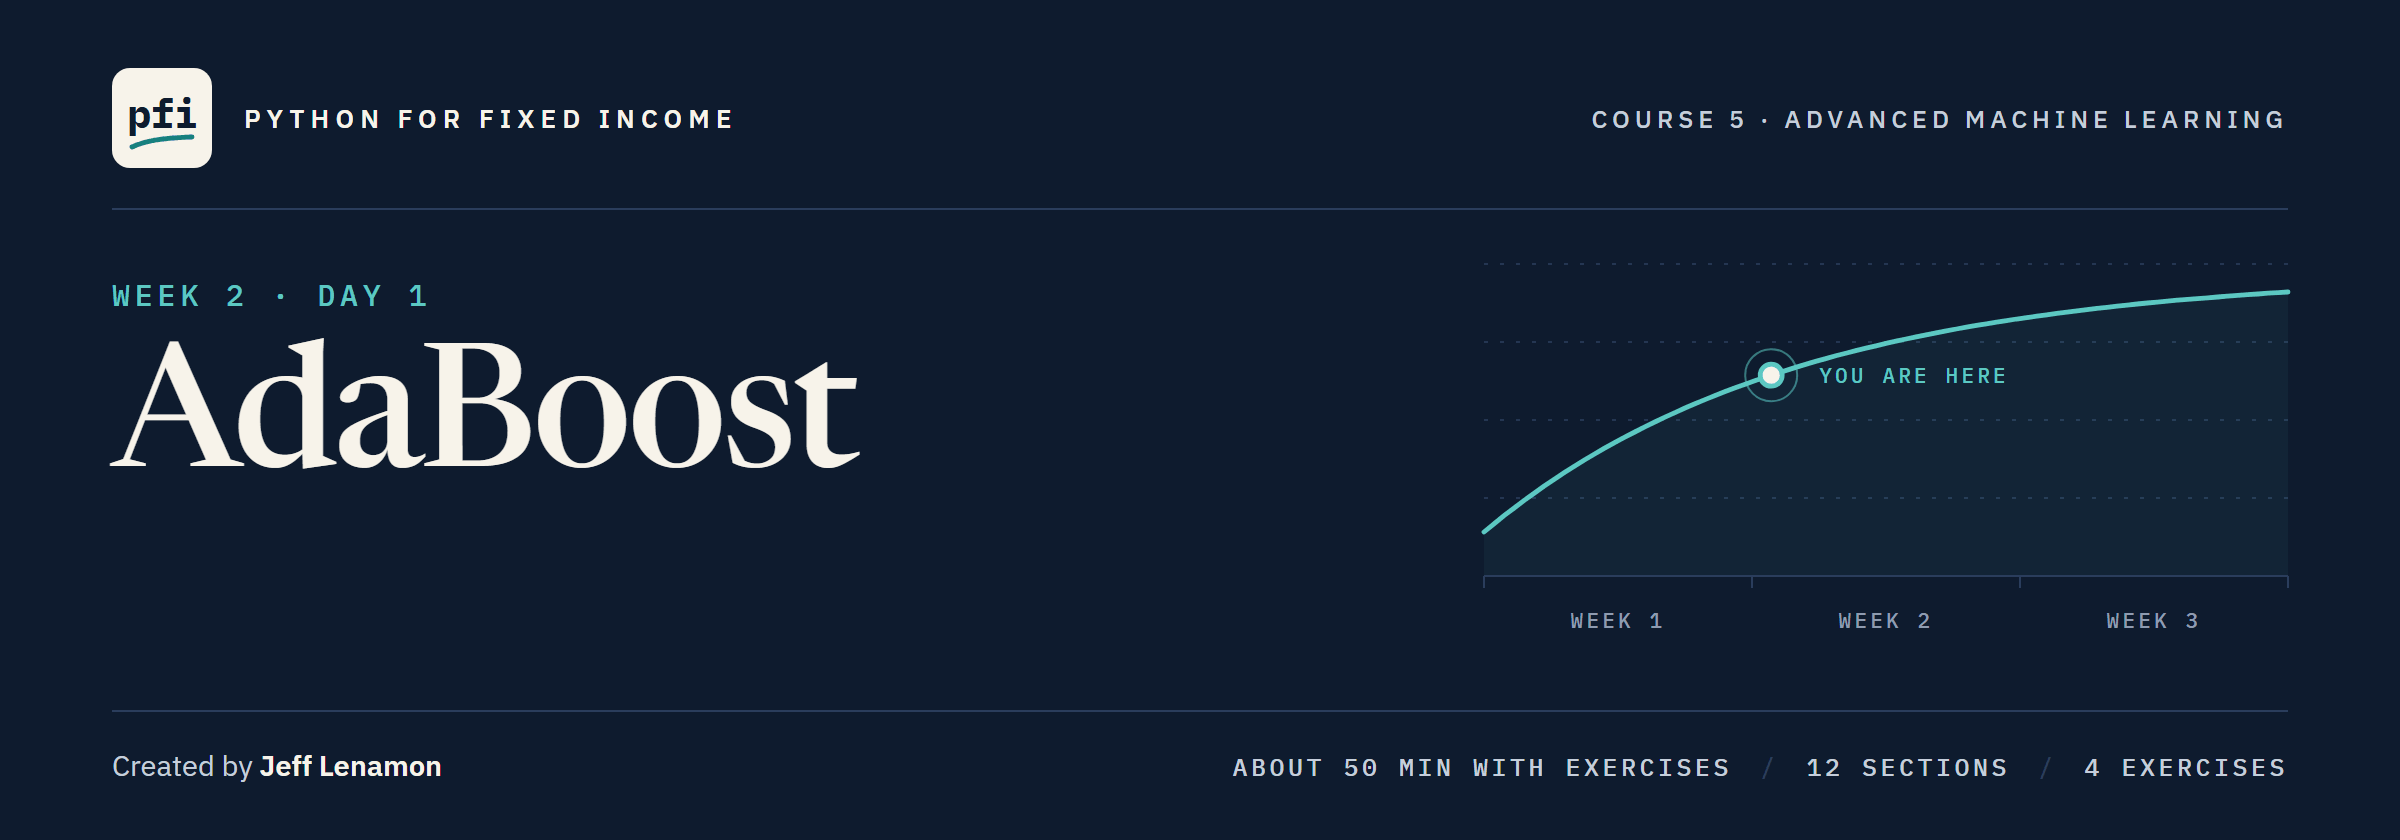

# AdaBoost

Week 2, Day 1. Fit one-question trees one after another, each on rows reweighted toward what the trees before it missed, and add them up as a weighted vote.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day1/06_adaboost.ipynb)

# Problem Statement

## Business Context

Week 1 averaged deep trees grown side by side, and the best of those averages passed Course 4's pruned tree.
The desk now tries the opposite bet: trees too small to be much good alone, one question each, fitted one after another, each told which accounts the trees before it keep getting wrong.
Does that rank the validation accounts as well, how does one round work, where does the attention go, and what is the number the model returns?
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Fit AdaBoost and score it on training and validation rows, then run one round by hand and match the library.
Follow where the row weights go, read the rounds, the learning rate and the member's depth from folds inside the training rows, take the model apart one column at a time, and read what its output is.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

## Your Route Through Day 1

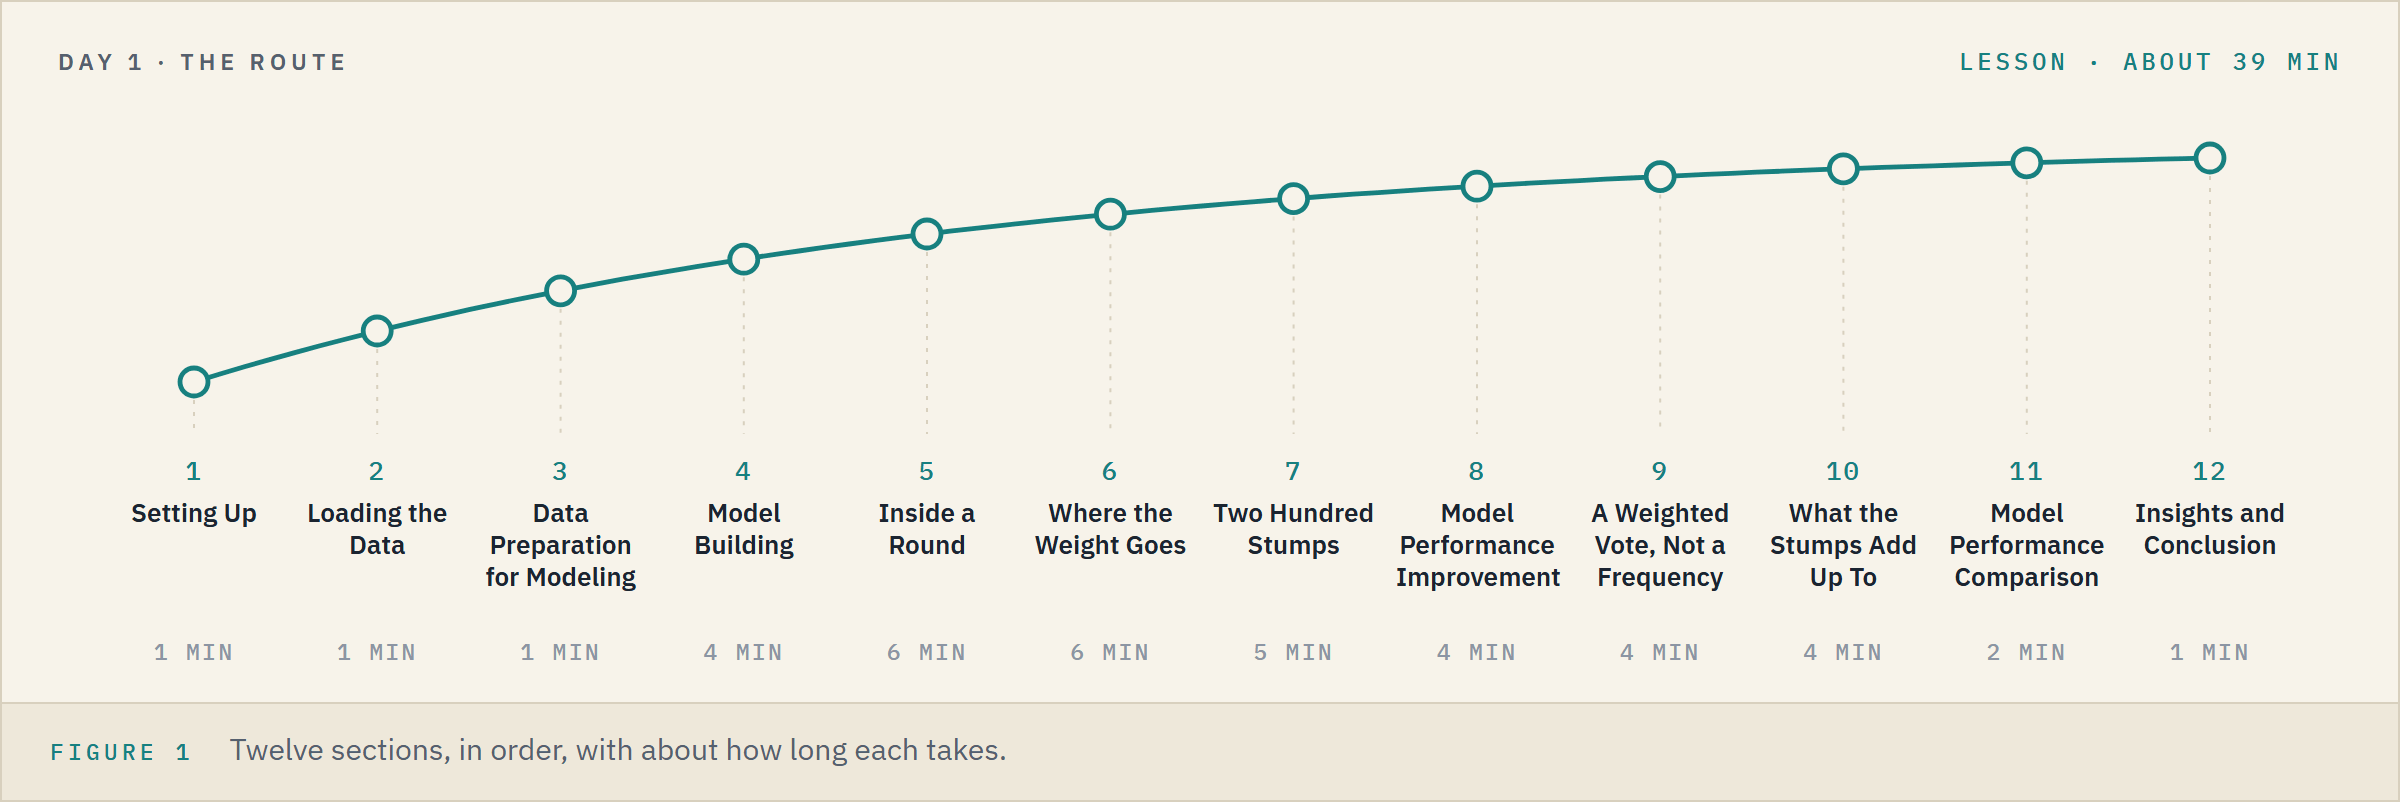

**Time.** About 39 minutes for the lesson, then about 12 for the four exercises.

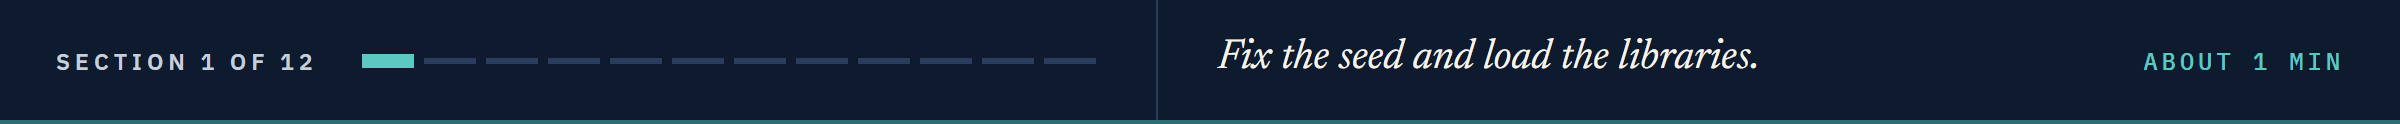

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, and to score settings on folds inside the training rows
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Course 4's models, Day 3's forests, and AdaBoost
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# to score a model's outputs
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score, f1_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

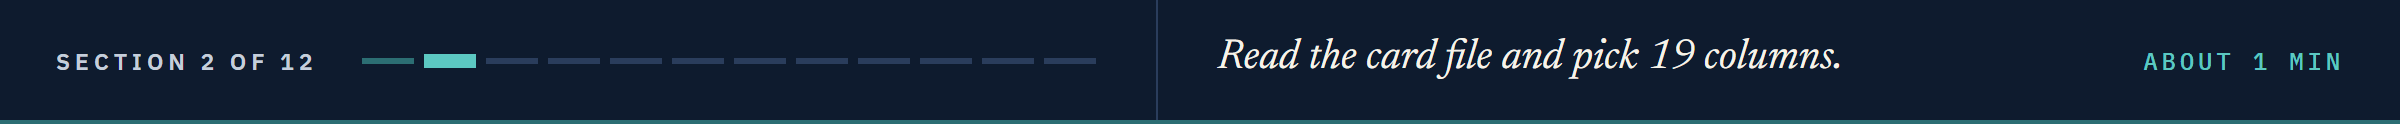

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we rebuild its rows exactly.**

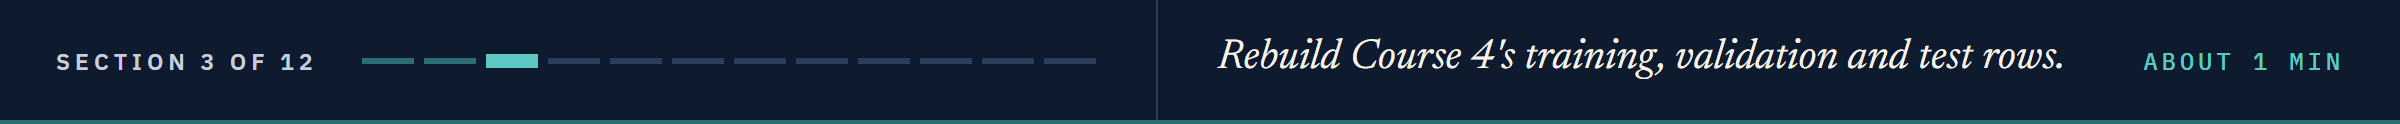

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


The same 18,000, 6,000 and 6,000 accounts as Course 4, each with the same default share.

Every model is reported on the validation rows; Course 5 chooses nothing on them, and never scores the test rows.

**Training rows fit, validation rows report, test rows stay closed.**

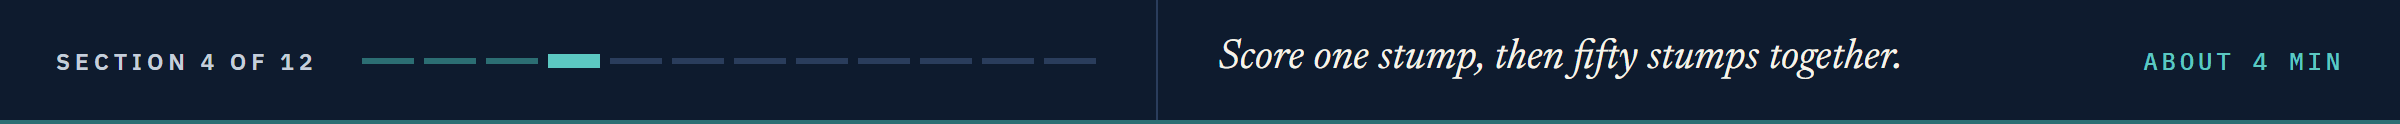

# Model Building

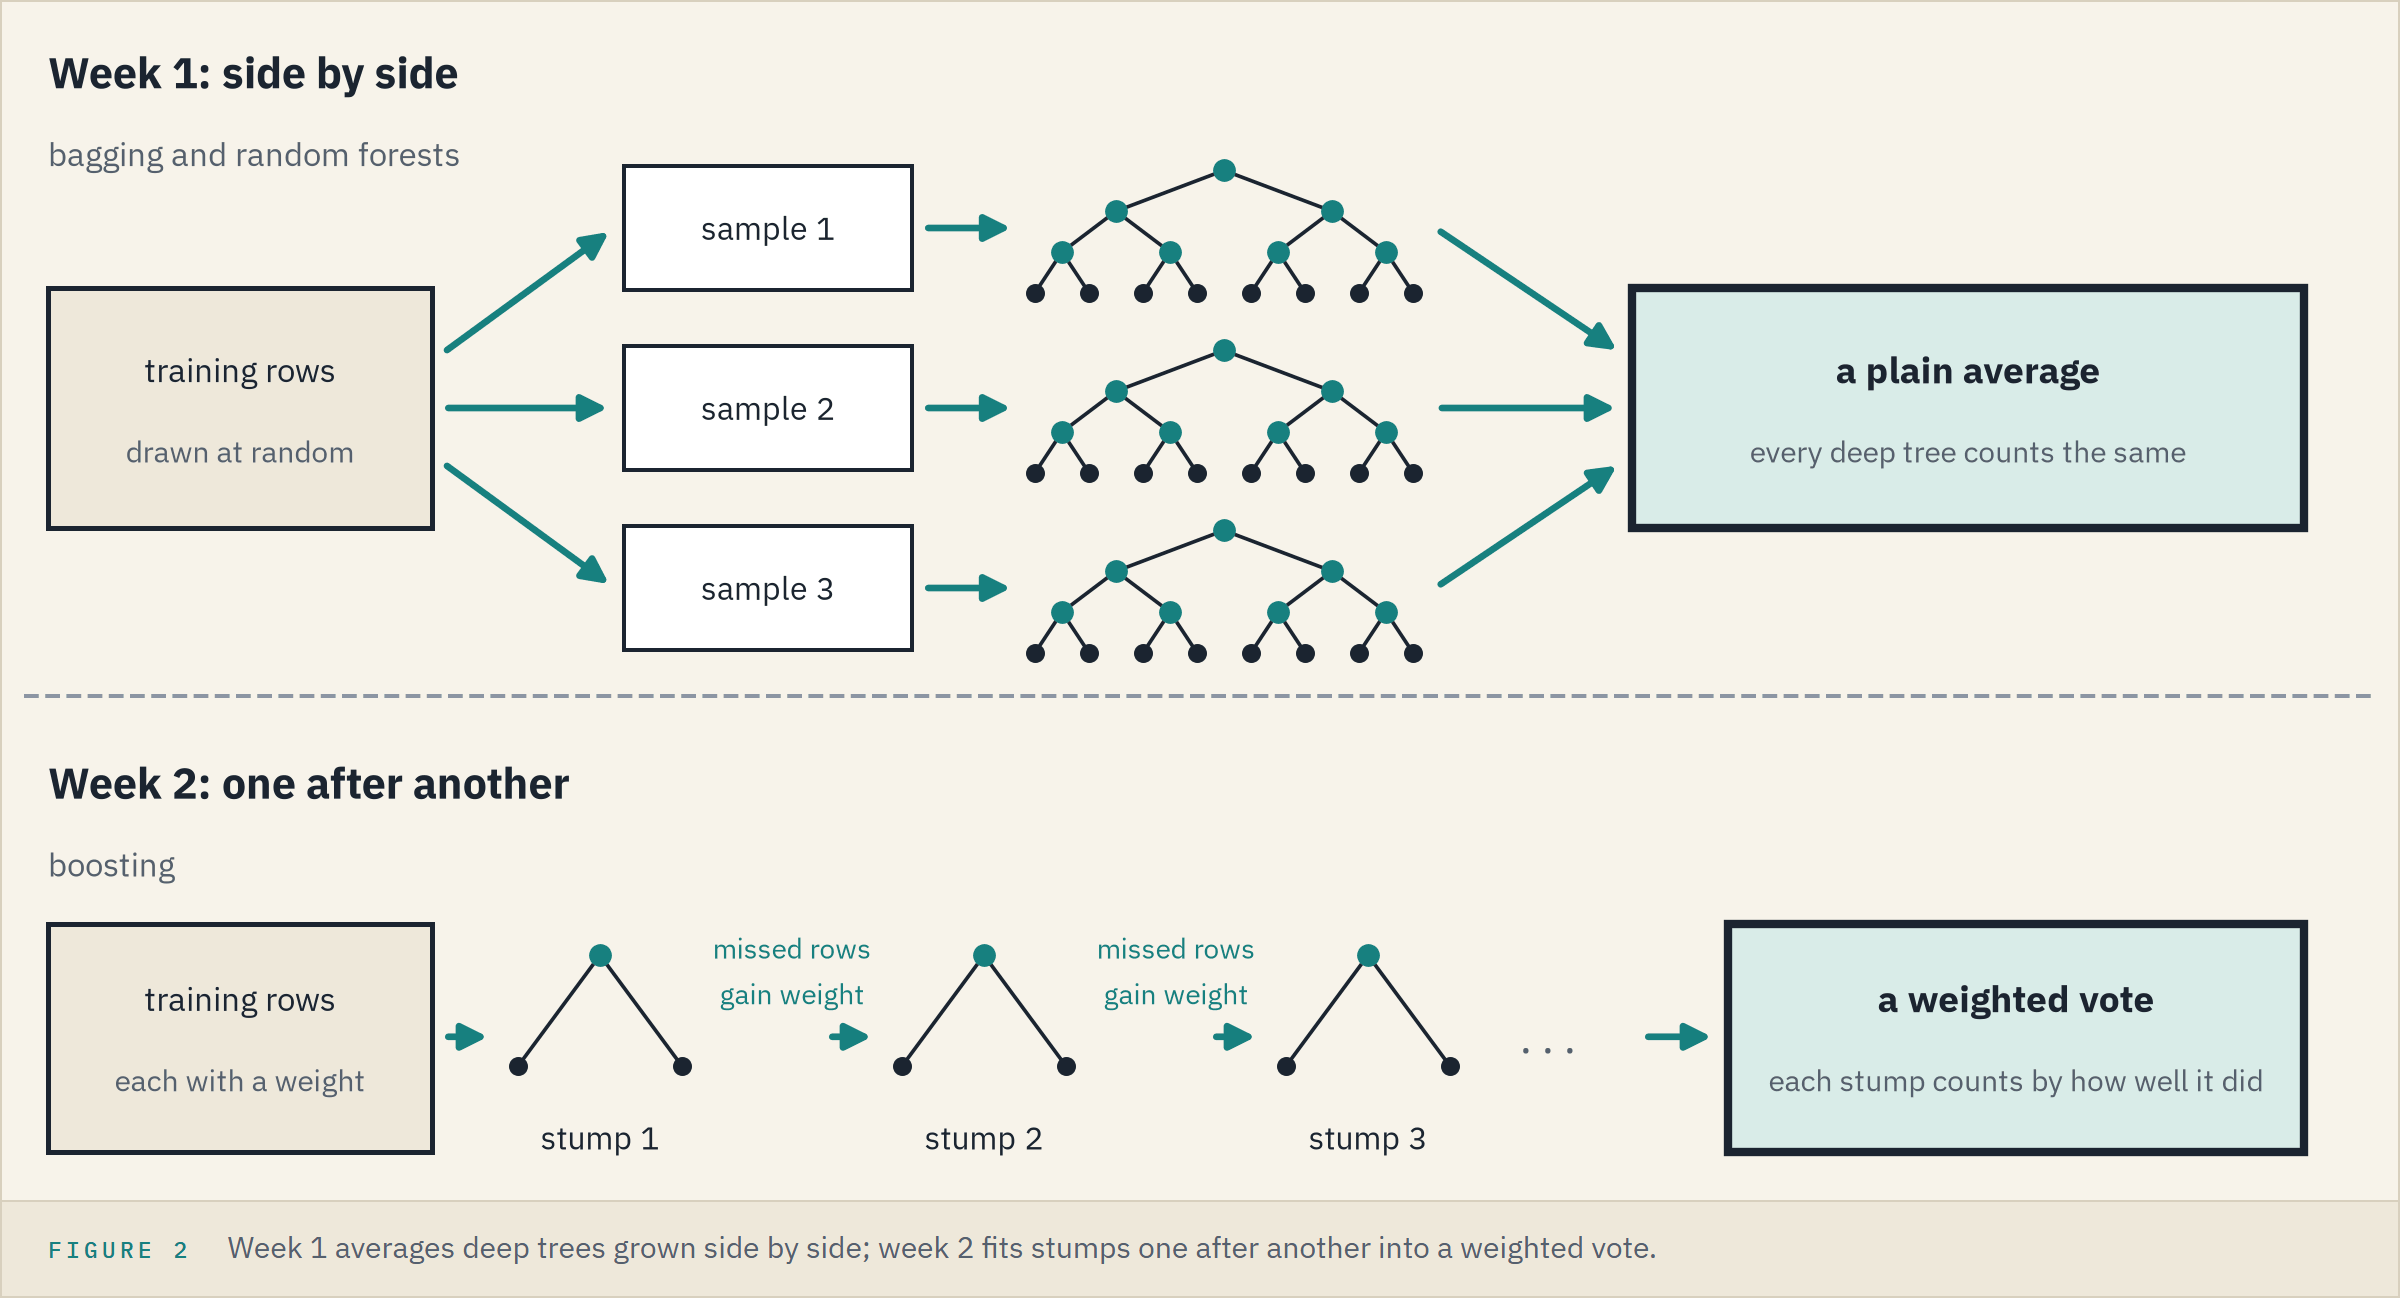

Week 1 grew deep trees side by side on bootstrap samples and averaged them.
**Boosting** grows small trees one after another: every training row carries a weight, and each new tree is fitted with more weight on the rows the trees before it got wrong.
Its usual member is a **stump**, Course 4's Day 9 one-question tree, too weak to be much good alone.

## One Stump

Course 4's Day 8 scoring function, repeated: ROC AUC, then four measures at a threshold.

In [6]:
# flag at or above the threshold, then ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [7]:
# Course 4's Day 9 stump, refitted: one question
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train)
print("Question:", FEATURES[stump.tree_.feature[0]], "<=", stump.tree_.threshold[0])

# the stump on the rows it was fitted on, and on the validation rows
stump_perf = pd.concat([model_performance_classification(stump, X_train, y_train),
                        model_performance_classification(stump, X_valid, y_valid)])
stump_perf.index = ["training", "validation"]
stump_perf

Question: PAY_0 <= 1.5


,ROC AUC,Accuracy,Recall,Precision,F1
training,0.6459,0.8209,0.3320,0.7013,0.4507
validation,0.6361,0.8160,0.3135,0.6831,0.4298


One question splits the accounts into two groups, so the stump gives only two outputs.

Its validation ROC AUC is 0.6361: it ranks, but coarsely.

## AdaBoost With the Library's Defaults

`AdaBoostClassifier` is scikit-learn's boosting of stumps.
`.get_params()`, Day 2's, returns every setting of a model as a dictionary.

In [8]:
# AdaBoost with every setting at the library's default, and three of its settings
ada50 = AdaBoostClassifier(random_state=SEED)
params = ada50.get_params()
print("Member:", params["estimator"], " Rounds:", params["n_estimators"], " Learning rate:", params["learning_rate"])

Member: None  Rounds: 50  Learning rate: 1.0


`estimator=None` means the default member: a stump.

`n_estimators` is the number of **rounds**, one stump fitted in each.

The learning rate waits for its own section.

In [9]:
# fit the 50 rounds, then score the training and the validation rows
ada50.fit(X_train, y_train)
ada50_perf = pd.concat([model_performance_classification(ada50, X_train, y_train),
                        model_performance_classification(ada50, X_valid, y_valid)])
ada50_perf.index = ["training", "validation"]
ada50_perf

,ROC AUC,Accuracy,Recall,Precision,F1
training,0.7760,0.8206,0.3353,0.6964,0.4526
validation,0.7672,0.8168,0.3195,0.6839,0.4355


### Interpretation of the Scores

Fifty stumps lift the validation ROC AUC from the stump's 0.6361 to 0.7672.

Training and validation sit less than a hundredth apart: little memorising.

At 0.5 the model flags only 32 percent of the defaults; thresholds wait for Day 10.

**Fifty one-question trees rank unseen accounts far better than one. Next: how each round decides what to ask.**

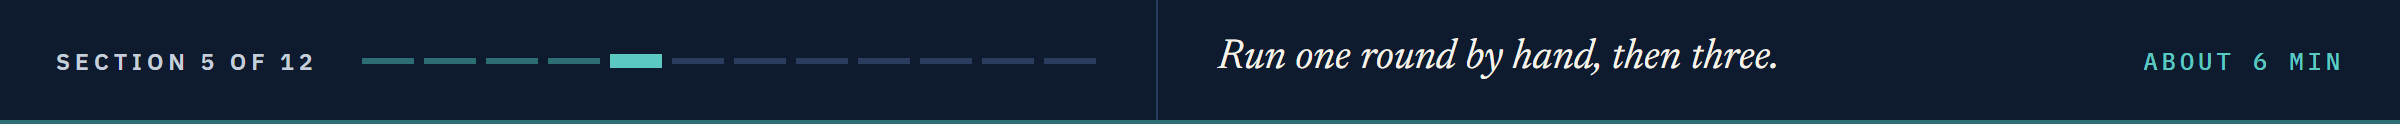

# Inside a Round

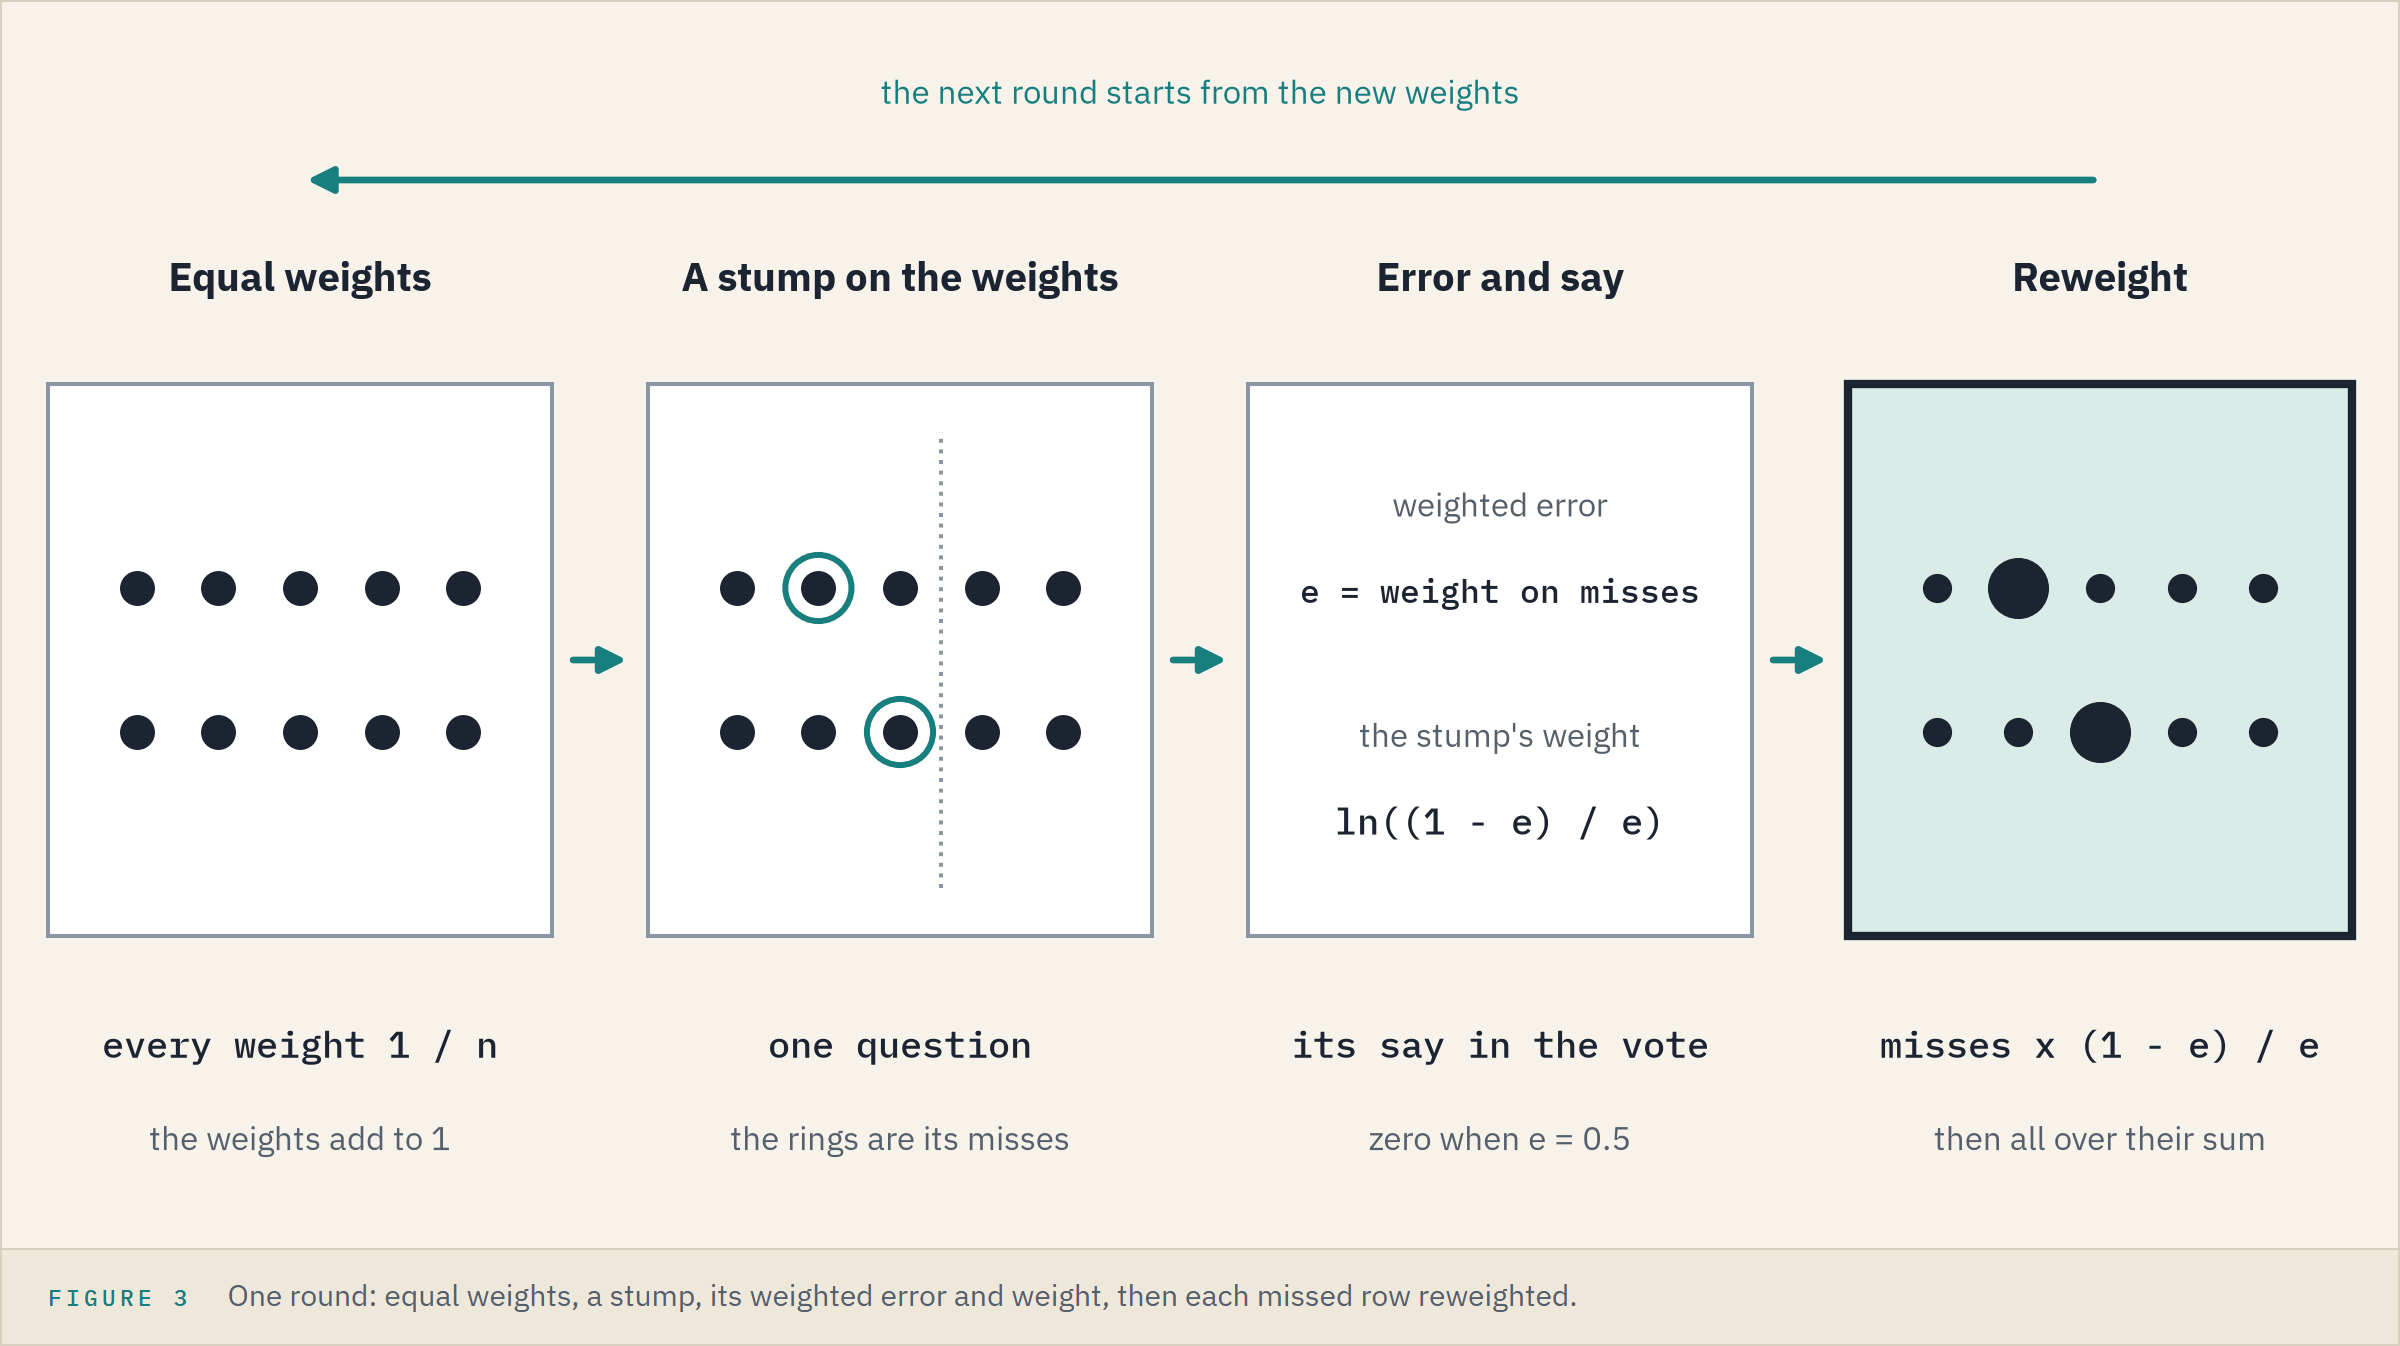

Every training row starts with the same weight, 1/n, and the weights always add to 1.
A round fits a stump on the weighted rows, then works out three things:

* the **weighted error** e: the share of the weight on the rows the stump misses
* the stump's **weight** in the vote, ln((1 - e) / e): large when e is small, zero at e = 0.5
* the new row weights: each missed row's weight times (1 - e) / e, then every weight divided by their sum

scikit-learn calls this recipe SAMME.

## Round One by Hand

In [10]:
# every training row starts with the same weight
n = len(X_train)
weights = np.full(n, 1 / n)

# 1 where the stump's flag differs from the outcome
outcome = y_train.to_numpy()
missed = (stump.predict(X_train) != outcome).astype(int)
print("Missed:", missed.sum(), "of", n)
print("Defaults left unflagged:", ((missed == 1) & (outcome == 1)).sum(), " Paid accounts flagged:", ((missed == 1) & (outcome == 0)).sum())

Missed: 3223 of 18000
Defaults left unflagged: 2660  Paid accounts flagged: 563


In [11]:
# the weighted error, and the stump's weight in the vote
error = (weights * missed).sum()
alpha = np.log((1 - error) / error)
print("Weighted error:", round(error, 4), " Stump's weight:", round(alpha, 4))

Weighted error: 0.1791  Stump's weight: 1.5228


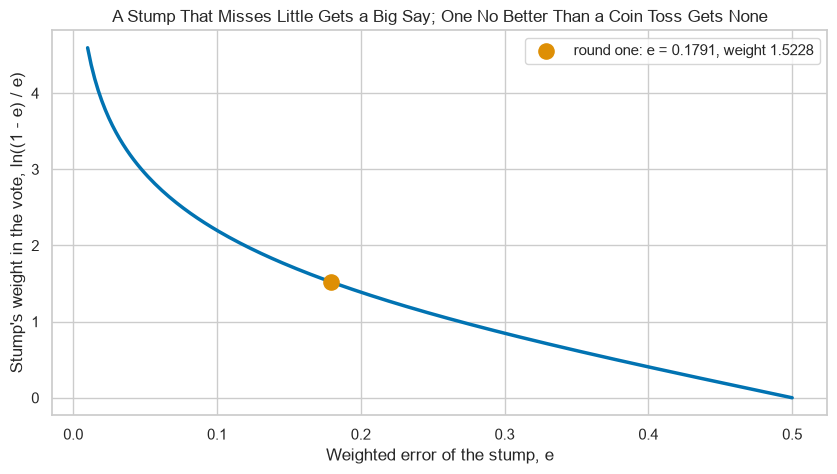

In [12]:
# the stump's weight for every weighted error from 0.01 to 0.5, round one marked
errors = np.linspace(0.01, 0.5, 200)
plt.plot(errors, np.log((1 - errors) / errors), linewidth=2.5)
plt.scatter(error, alpha, s=120, color="C1", zorder=3, label=f"round one: e = {error:.4f}, weight {alpha:.4f}")
plt.xlabel("Weighted error of the stump, e")
plt.ylabel("Stump's weight in the vote, ln((1 - e) / e)")
plt.title("A Stump That Misses Little Gets a Big Say; One No Better Than a Coin Toss Gets None")
plt.legend()
plt.show()

Round one's stump misses 3,223 accounts: 2,660 defaults on its paid side and 563 paid accounts on its flagged side.

Equal weights make the weighted error the plain share missed, 0.1791, and the stump's weight 1.5228.

**Predict 1**

The missed rows hold 0.1791 of the weight before the reweighting.

Q. What share of the weight do they hold after it? Write down a number.

## Reweighting the Rows

In [13]:
# missed rows times (1 - e) / e, which is np.exp of the stump's weight; then every weight over their sum
new_weights = weights * np.exp(alpha * missed)
new_weights = new_weights / new_weights.sum()
print("Missed rows' share of the weight: before", round(weights[missed == 1].sum(), 4), " after", round(new_weights[missed == 1].sum(), 4))
print("A missed row now weighs", round(new_weights.max() / new_weights.min(), 4), "times a correct row")

Missed rows' share of the weight: before 0.1791  after 0.5
A missed row now weighs 4.5849 times a correct row


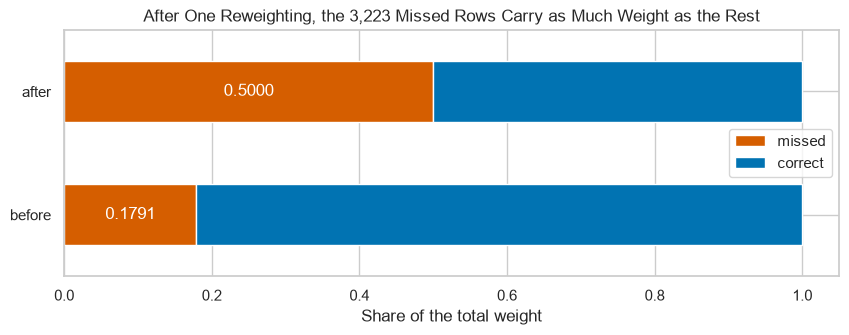

In [14]:
# the weight on missed and on correct rows, before and after the reweighting
shares = pd.DataFrame({"missed": [weights[missed == 1].sum(), new_weights[missed == 1].sum()],
                       "correct": [weights[missed == 0].sum(), new_weights[missed == 0].sum()]}, index=["before", "after"])
ax = shares.plot.barh(stacked=True, color=["C3", "C0"], figsize=(10, 3.2))
ax.bar_label(ax.containers[0], fmt="%.4f", label_type="center", color="white")
ax.set_xlabel("Share of the total weight")
ax.set_title("After One Reweighting, the 3,223 Missed Rows Carry as Much Weight as the Rest")
ax.legend(loc="center right")
plt.show()

The missed rows now hold half the weight, and each weighs (1 - e) / e = 4.5849 times a correct row.

On the new weights round one's stump is right on exactly half: a coin toss, so round two must ask something else.

## Three Rounds Against the Library

`fit(X, y, sample_weight=weights)` fits a tree with each row counted by its weight.

In [15]:
# one round: fit a stump on the weights, then the weighted error, the stump's weight and the new weights
def boost_round(weights):
    member = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train, sample_weight=weights)
    missed = (member.predict(X_train) != outcome).astype(int)
    error = (weights * missed).sum()
    alpha = np.log((1 - error) / error)
    new_weights = weights * np.exp(alpha * missed)
    return member, error, alpha, new_weights / new_weights.sum()

In [16]:
# three rounds from equal weights; each round's question, error and weight kept
weights = np.full(n, 1 / n)
hand = []
for r in range(3):
    member, error, alpha, weights = boost_round(weights)
    hand.append([FEATURES[member.tree_.feature[0]] + " <= " + str(member.tree_.threshold[0]), error, alpha])
hand = pd.DataFrame(hand, columns=["question", "error", "weight"], index=[1, 2, 3])

# the library keeps each stump's error and weight: its first three beside ours
hand["library's error"] = ada50.estimator_errors_[:3]
hand["library's weight"] = ada50.estimator_weights_[:3]
hand

,question,error,weight,library's error,library's weight
1,PAY_0 <= 1.5,0.1791,1.5228,0.1791,1.5228
2,PAY_AMT1 <= 1223.5,0.4128,0.3526,0.4128,0.3526
3,PAY_3 <= 1.5,0.4356,0.2592,0.4356,0.2592


Three rounds, three different questions: the September status, the September payment, the July status.

Each error is closer to 0.5 than the last, so each stump gets less say.

Our errors and weights equal `.estimator_errors_` and `.estimator_weights_`.

**`AdaBoostClassifier` is these steps, repeated.**

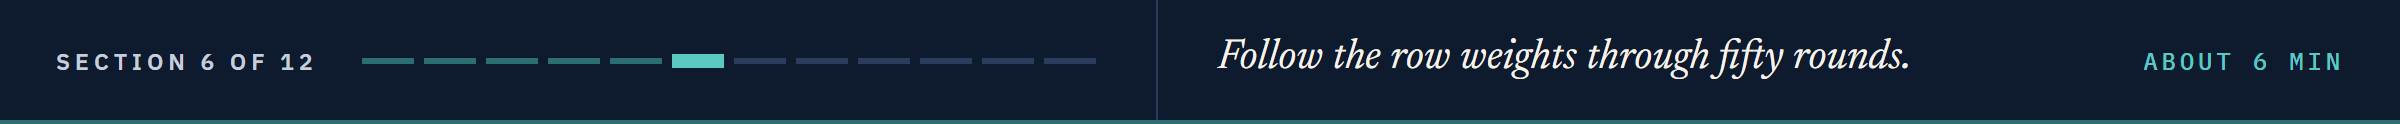

# Where the Weight Goes

**Predict 2**

The defaulted accounts are 22.12 percent of the training rows, so they start with 0.2212 of the weight.

Q. After 50 rounds, what share of the weight do they hold? Write down a number.

## Fifty Rounds of Weights

In [17]:
# fifty rounds from equal weights; history[k] is the weights after round k
weights = np.full(n, 1 / n)
history = [weights]
alphas = []
for r in range(50):
    member, error, alpha, weights = boost_round(weights)
    history.append(weights)
    alphas.append(alpha)
print("Largest gap to the library's 50 stump weights:", f"{np.abs(np.array(alphas) - ada50.estimator_weights_).max():.1e}")

Largest gap to the library's 50 stump weights: 1.7e-15


In [18]:
# the defaulted accounts' share of the weight after rounds 0, 1, 3 and 50
for k in [0, 1, 3, 50]:
    print(f"After round {k}: {history[k][outcome == 1].sum():.4f}")

After round 0: 0.2212
After round 1: 0.4574
After round 3: 0.5238
After round 50: 0.5056


Our 50 rounds match the library's to the last digit a computer keeps.

The defaulted accounts double their share in round one, then hold about half the weight.

### Your Turn: Step Through the Rounds

The **weight map** draws 400 training accounts, picked once at random: the September status across (with a small seeded shift so dots do not sit on one line), the credit limit up, and each dot's area the account's weight.

In [19]:
# 400 training accounts, and where each sits on the map
rng = np.random.default_rng(SEED)
shown = rng.choice(n, size=400, replace=False)
across = X_train["PAY_0"].to_numpy()[shown].clip(max=3) + rng.uniform(-0.35, 0.35, size=400)
limit = X_train["LIMIT_BAL"].to_numpy()[shown]

# the weight map after round k: dot area is the weight against the start, colour the outcome
def weight_map(k, ax):
    for value, colour, name in [(0, "C0", "paid"), (1, "C3", "defaulted")]:
        rows = outcome[shown] == value
        ax.scatter(across[rows], limit[rows], s=history[k][shown][rows] * n * 40, color=colour, alpha=0.6,
                   edgecolor="white", linewidth=0.5, label=name)
    ax.set(yscale="log", xticks=range(-2, 4), xticklabels=["-2", "-1", "0", "1", "2", "3+"], title=f"After round {k}",
           yticks=[1e4, 3e4, 1e5, 3e5, 1e6], yticklabels=["10k", "30k", "100k", "300k", "1m"])

Drag the slider through the rounds and watch which dots grow.

In [20]:
# your turn: drag the slider through the rounds
def draw_weights(round_number=0):
    fig, ax = plt.subplots(figsize=(10, 6))
    weight_map(round_number, ax)
    ax.set(xlabel="September status (PAY_0), 3 and above together", ylabel="Credit limit (NT dollars, log scale)")
    ax.legend(loc="lower right")
    plt.show()

interact(draw_weights, round_number=(0, 50, 1));

interactive(children=(IntSlider(value=0, description='round_number', max=50), Output()), _dom_classes=('widget…

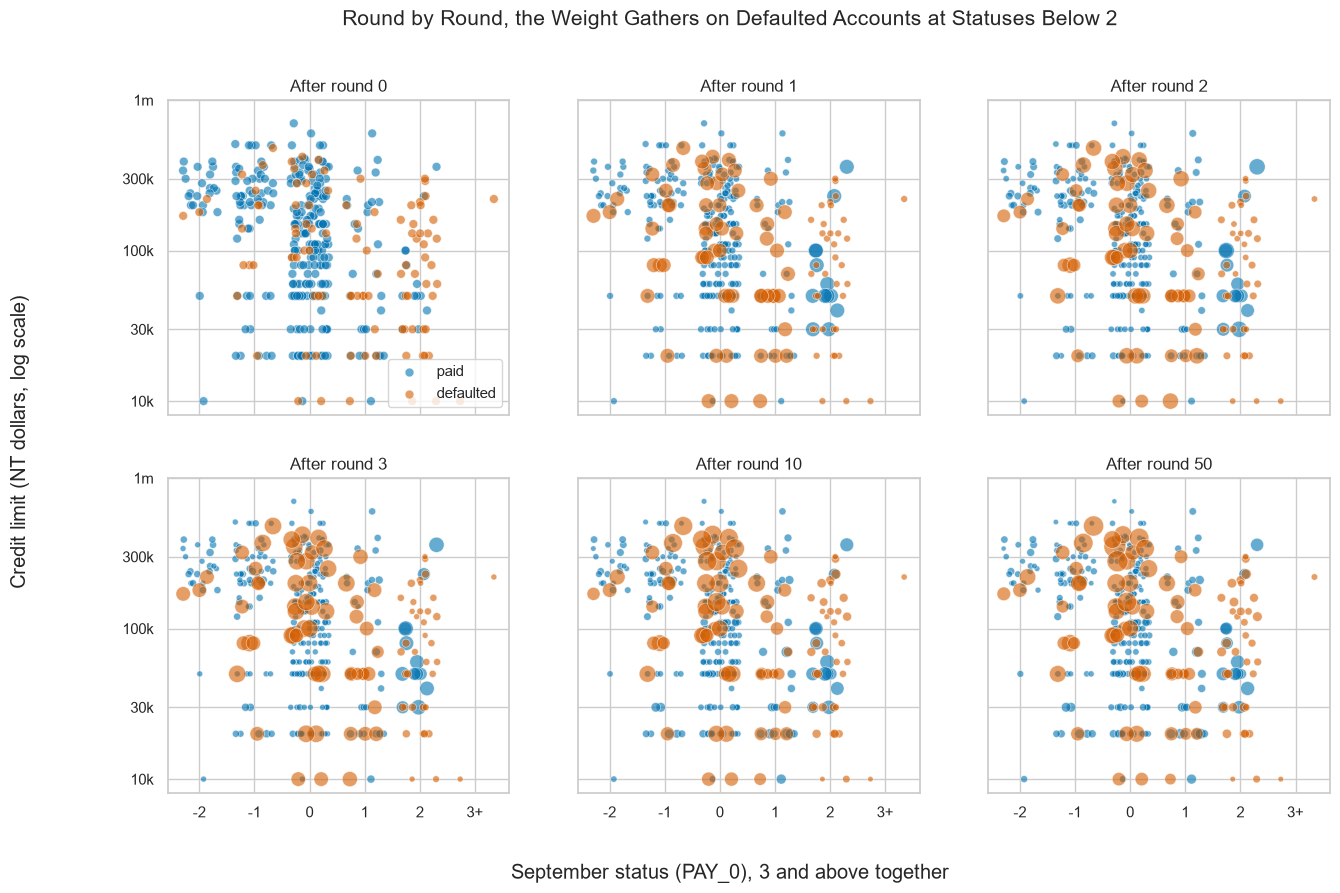

In [21]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, k in zip(axes.flat, [0, 1, 2, 3, 10, 50]):
    weight_map(k, ax)
axes[0, 0].legend(loc="lower right")

# supxlabel and supylabel label the whole figure, as suptitle titles it
fig.supxlabel("September status (PAY_0), 3 and above together")
fig.supylabel("Credit limit (NT dollars, log scale)")
fig.suptitle("Round by Round, the Weight Gathers on Defaulted Accounts at Statuses Below 2", fontsize=15)
plt.show()

At round 0 every dot is the same size.

Round one swells the defaulted dots at statuses -2 to 1 and the paid dots at 2 and above: the stump's misses.

By round 50 the largest dots are defaulted accounts at statuses -2 to 1, across every credit limit.

## Who Carries the Weight

Here **late** means a September status of 2 or more, the stump's own cut.

In [22]:
# four groups: outcome by late or not
late = X_train["PAY_0"].to_numpy() >= 2
groups = pd.Series(np.where(outcome == 1, "defaulted", "paid")) + np.where(late, ", late", ", not late")

# each group's share of the weight after every round; .add_prefix() puts "round " before each column name
group_share = pd.DataFrame([pd.Series(w).groupby(groups).sum() for w in history])
group_share.loc[[0, 50]].T.add_prefix("round ")

,round 0,round 50
"defaulted, late",0.0734,0.0633
"defaulted, not late",0.1478,0.4423
"paid, late",0.0313,0.0719
"paid, not late",0.7475,0.4225


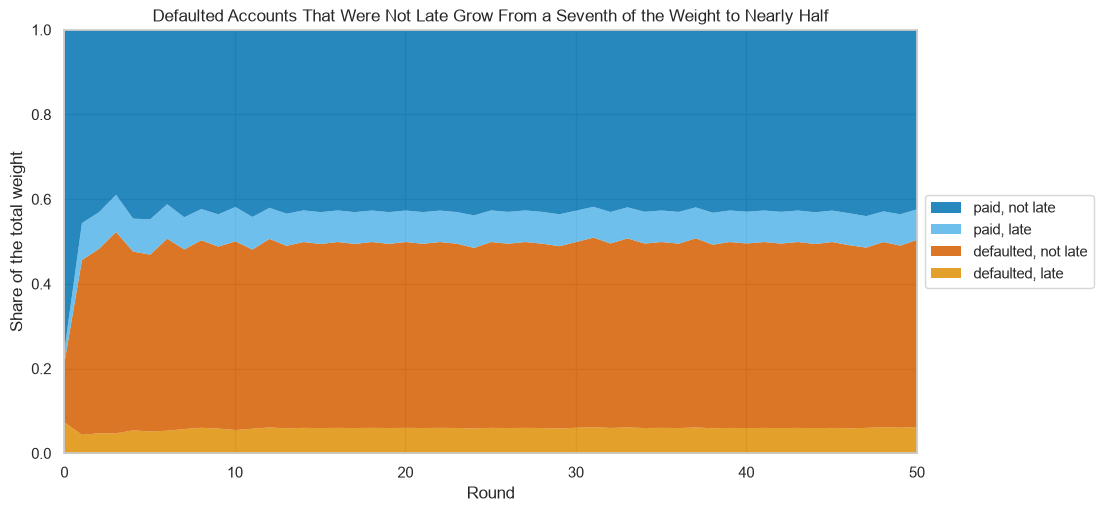

In [23]:
# the four shares stacked, round by round: .plot.area() is pandas' stacked area, and reverse=True lists the legend top down
ax = group_share.plot.area(color=["C1", "C3", "C9", "C0"], alpha=0.85, linewidth=0, figsize=(11, 5.5))
ax.set(xlim=(0, 50), ylim=(0, 1), xlabel="Round", ylabel="Share of the total weight")
ax.set_title("Defaulted Accounts That Were Not Late Grow From a Seventh of the Weight to Nearly Half")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), reverse=True)
plt.show()

In [24]:
# after round 50: each row's weight against its start, and the rows at three times or more
times = history[50] * n
heavy = times >= 3
print("Weight against the start:", round(times.min(), 2), "to", round(times.max(), 2))
print("Rows at 3 times or more:", heavy.sum(), " Their share of the weight:", round(history[50][heavy].sum(), 4))
print("Of them defaulted:", round(outcome[heavy].mean() * 100, 1), "percent  Late:", round(late[heavy].mean() * 100, 1), "percent")

Weight against the start: 0.29 to 6.63
Rows at 3 times or more: 1309  Their share of the weight: 0.2782
Of them defaulted: 93.4 percent  Late: 6.6 percent


Paid accounts that were not late fall from 0.7475 of the weight to 0.4225; defaulted accounts that were not late rise from 0.1478 to 0.4423.

After 50 rounds a row weighs 0.29 to 6.63 times its start.

The 1,309 rows at three times or more hold 0.2782 of the weight: 93.4 percent defaulted, 6.6 percent late.

**The weight piles onto accounts that defaulted while their September status was not late: the cases a question about the September status cannot see.**

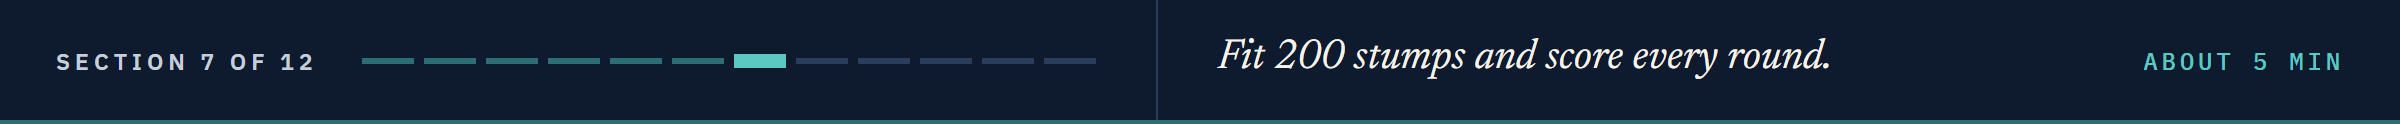

# Two Hundred Stumps

## Fitting the Main Model

In [25]:
# 200 rounds, the member written out: a stump
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=200, random_state=SEED)
ada.fit(X_train, y_train)
print(len(ada.estimators_), "stumps")

200 stumps


## Which Column Each Round Asks

`.estimators_` holds the fitted members, as in Day 2's bag.

In [26]:
# the column each stump asks, by round, and how many rounds ask each column
asked = pd.Series([FEATURES[m.tree_.feature[0]] for m in ada.estimators_], index=range(1, 201))
counts = asked.value_counts()
print("Columns asked:", len(counts))
print(counts.head(3).to_dict(), " Asked once:", list(counts[counts == 1].index))

Columns asked: 19
{'PAY_0': 40, 'PAY_AMT3': 28, 'BILL_AMT1': 26}  Asked once: ['PAY_6', 'PAY_AMT4']


An **event plot** marks each moment something happens: here, one row per column and a tick at every round that asks it.
`ax.eventplot` draws one row of ticks for each list of positions.

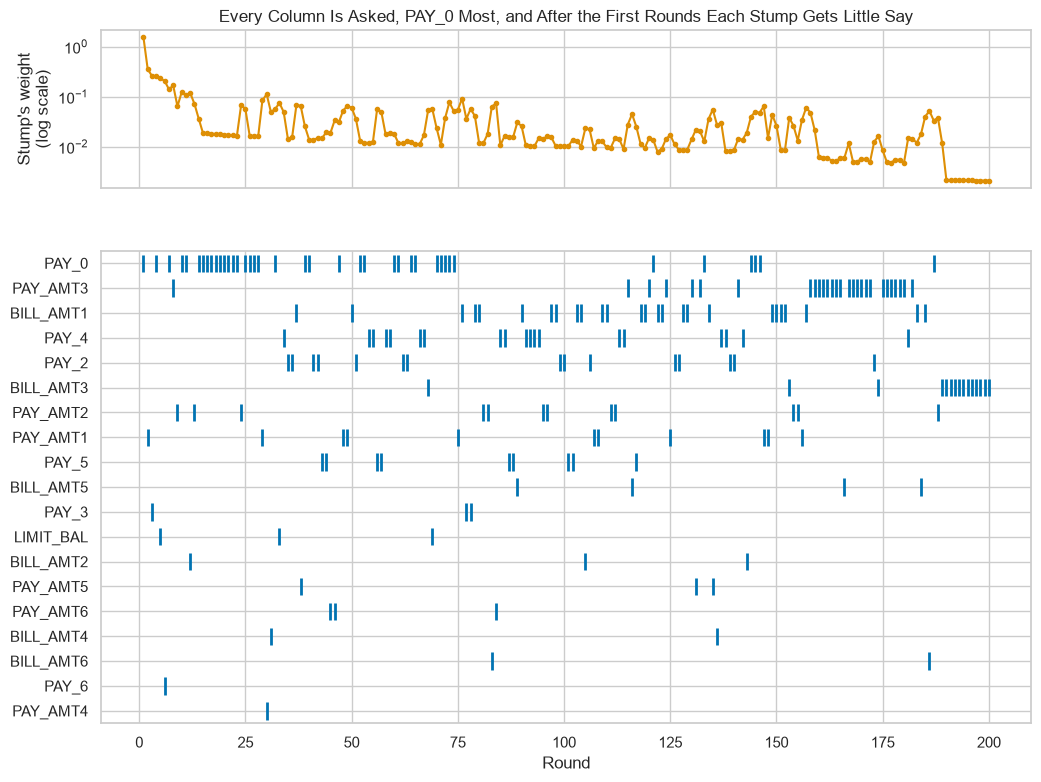

In [27]:
# above: each stump's weight in the vote by round; below: an event plot of the column each round asks
fig, (top, ax) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, height_ratios=[1, 3])
top.plot(range(1, 201), ada.estimator_weights_, color="C1", marker=".")
top.set(yscale="log", ylabel="Stump's weight\n(log scale)")
ax.eventplot([asked.index[asked == column] for column in counts.index], lineoffsets=range(len(counts)),
             linelengths=0.7, linewidths=2, colors="C0")
ax.set(yticks=range(len(counts)), yticklabels=counts.index, ylim=(len(counts) - 0.5, -0.5), xlabel="Round")
top.set_title("Every Column Is Asked, PAY_0 Most, and After the First Rounds Each Stump Gets Little Say")
plt.show()

In [28]:
# the errors and weights from round 20 on, and round one's share of the vote's total weight
print("Rounds 20 to 200: error", round(ada.estimator_errors_[19:].min(), 4), "to", round(ada.estimator_errors_[19:].max(), 4),
      " weight", round(ada.estimator_weights_[19:].min(), 4), "to", round(ada.estimator_weights_[19:].max(), 4))
print("Round one's share of the total weight:", round(ada.estimator_weights_[0] / ada.estimator_weights_.sum(), 4))

Rounds 20 to 200: error 0.4721 to 0.4995  weight 0.0021 to 0.1117
Round one's share of the total weight: 0.1923


All 19 columns are asked: `PAY_0` in 40 rounds, `PAY_AMT3` in 28, `BILL_AMT1` in 26.

From round 20 on every error sits just under 0.5, so each stump gets a small weight.

Round one alone holds about a fifth of the vote.

**Predict 3**

Q. Sketch training and validation ROC AUC from round 1 to round 200 on one chart: where do they start, and how far apart do they end?

## Training Against Validation, Round by Round

`.staged_decision_function(rows)` gives the model's output for the rows after round 1, after round 2, and so on.
That output, `.decision_function`, ranks the accounts as `predict_proba` does; what it is comes later.

In [29]:
# ROC AUC of the model as it stood after every round, on the training and the validation rows
train_auc = [roc_auc_score(y_train, d) for d in ada.staged_decision_function(X_train)]
valid_auc = [roc_auc_score(y_valid, d) for d in ada.staged_decision_function(X_valid)]
staged = pd.DataFrame({"training": train_auc, "validation": valid_auc}, index=range(1, 201))
staged.loc[[1, 10, 50, 200]]

,training,validation
1,0.6459,0.6361
10,0.7661,0.7598
50,0.7760,0.7672
200,0.7867,0.7708


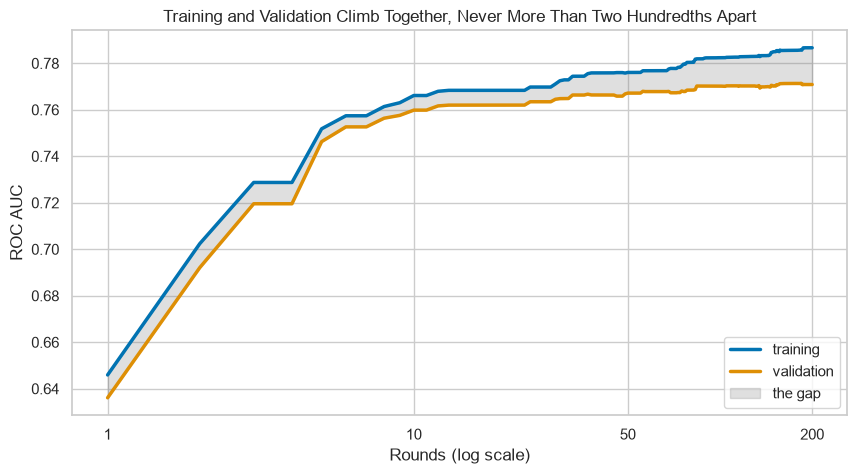

In [30]:
# the two curves on a log axis, the gap between them shaded
plt.plot(staged.index, staged["training"], linewidth=2.5, label="training")
plt.plot(staged.index, staged["validation"], linewidth=2.5, label="validation")
plt.fill_between(staged.index, staged["validation"], staged["training"], color="gray", alpha=0.25, label="the gap")
plt.xscale("log")
plt.xticks([1, 10, 50, 200], ["1", "10", "50", "200"])
plt.xlabel("Rounds (log scale)")
plt.ylabel("ROC AUC")
plt.title("Training and Validation Climb Together, Never More Than Two Hundredths Apart")
plt.legend(loc="lower right")
plt.show()

In [31]:
# the widest gap, the validation curve's highest point, and the 200-stump model's table
print("Largest gap:", round((staged["training"] - staged["validation"]).max(), 4))
print(f"Validation highest at round {staged['validation'].idxmax()}: {staged['validation'].max():.4f}")
print("Validation average precision:", round(average_precision_score(y_valid, ada.predict_proba(X_valid)[:, 1]), 4))
model_performance_classification(ada, X_valid, y_valid)

Largest gap: 0.0158
Validation highest at round 184: 0.7714
Validation average precision: 0.5321


,ROC AUC,Accuracy,Recall,Precision,F1
0,0.7708,0.8177,0.3293,0.6817,0.4441


Both curves start at the stump's scores and rise fastest in the first ten rounds.

After 200 rounds training reads 0.7867 and validation 0.7708; the gap never passes 0.0158.

The validation curve tops out at round 184; validation rows report, so that chooses nothing.

**A sum of one-question steps has little room to memorise. How many rounds, at what step, with how big a member? Folds inside the training rows decide.**

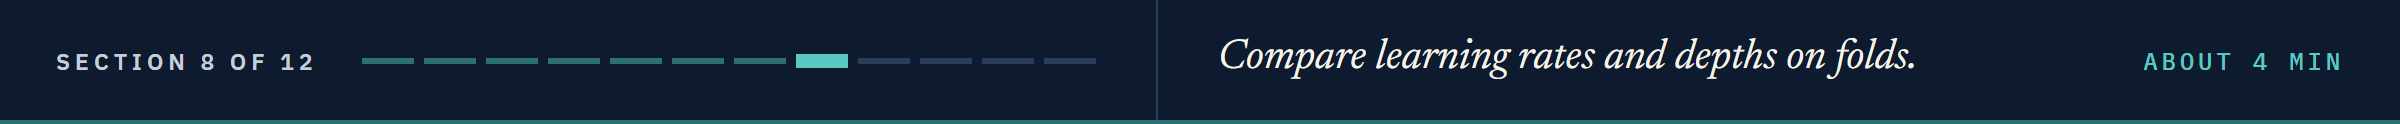

# Model Performance Improvement

The **learning rate** multiplies every stump's weight, in the vote and in the reweighting.
At 0.1 each stump gets a tenth of its say and the row weights move less each round, so more rounds are needed; the library's default is 1.0.

**Predict 4**

Q. After one round, how far apart will the held-out ROC AUC be at learning rates 0.1 and 1.0? Write down a number.

## Three Learning Rates on Five Folds

The fold loop is the one from Course 4's Day 5: fit on four folds, score the fifth, five times.

In [32]:
# AdaBoost with a member of the given depth, at the given learning rate, for the given rounds
def boosted(depth=1, rate=1.0, rounds=200):
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth, random_state=SEED),
                              n_estimators=rounds, learning_rate=rate, random_state=SEED)

# five folds inside the training rows, the same for every setting
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [33]:
# for each rate: fit on four folds, score the held-out fold after every round, then average over the folds
curves = {}
for rate in [0.1, 0.5, 1.0]:
    fold_auc = []
    for fit_rows, held_rows in folds.split(X_train, y_train):
        model = boosted(rate=rate).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
        fold_auc.append([roc_auc_score(y_train.iloc[held_rows], d) for d in model.staged_decision_function(X_train.iloc[held_rows])])
    curves[rate] = np.mean(fold_auc, axis=0)
curves = pd.DataFrame(curves, index=range(1, 201))
curves.loc[[1, 10, 50, 200]]

,0.1000,0.5000,1.0000
1,0.6459,0.6459,0.6459
10,0.7277,0.7626,0.7574
50,0.7686,0.7704,0.7688
200,0.7712,0.7738,0.7749


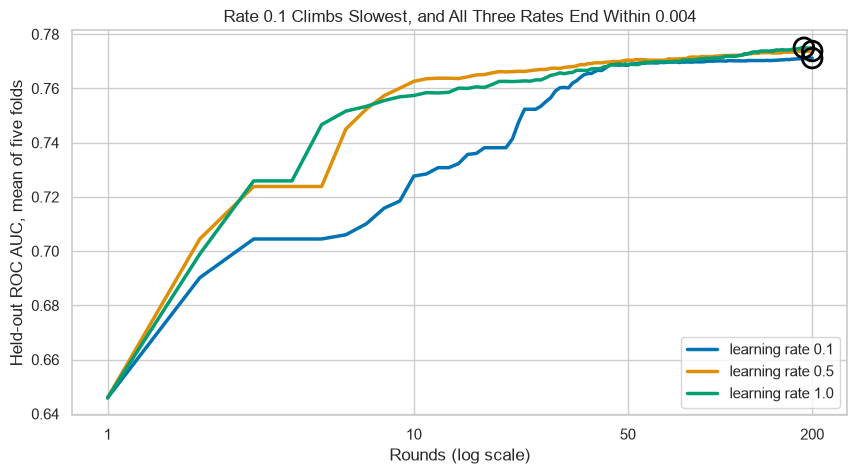

In [34]:
# one held-out curve per learning rate, each curve's highest round ringed
for rate in curves:
    plt.plot(curves.index, curves[rate], linewidth=2.5, label=f"learning rate {rate}")
    best = curves[rate].idxmax()
    plt.scatter(best, curves[rate].max(), s=200, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
plt.xscale("log")
plt.xticks([1, 10, 50, 200], ["1", "10", "50", "200"])
plt.xlabel("Rounds (log scale)")
plt.ylabel("Held-out ROC AUC, mean of five folds")
plt.title("Rate 0.1 Climbs Slowest, and All Three Rates End Within 0.004")
plt.legend(loc="lower right")
plt.show()

In [35]:
# each rate's highest held-out ROC AUC and the round it comes at
print(pd.DataFrame({"round": curves.idxmax(), "highest": curves.max()}))

        round  highest
0.1000    200   0.7712
0.5000    200   0.7738
1.0000    188   0.7750


After one round the three curves agree: one stump, scaled, ranks the accounts the same way at any rate.

After ten rounds rate 0.1 lags; by 200 rounds all three sit within 0.004 of each other.

The rate and the rounds trade: a smaller step needs more of them.

## Deeper Members

`cross_validate(..., return_train_score=True)`, Day 5's, scores the fitted folds beside the held-out ones.
Depths 2 and 3 get 100 rounds, half the stumps' 200, to keep the run short.

In [36]:
# rate 1.0 with members of depth 1, 2 and 3, on the same folds: 200 stumps, 100 deeper members
depth_scores = []
for depth, rounds in [(1, 200), (2, 100), (3, 100)]:
    cv = cross_validate(boosted(depth=depth, rounds=rounds), X_train, y_train, cv=folds, scoring="roc_auc",
                        return_train_score=True, n_jobs=1)
    depth_scores.append({"depth": depth, "fitted": cv["train_score"].mean(), "held out": cv["test_score"].mean(),
                         "held-out sd": cv["test_score"].std(), "folds": cv["test_score"]})
depth_scores = pd.DataFrame(depth_scores).set_index("depth")
depth_scores[["fitted", "held out", "held-out sd"]]

,fitted,held out,held-out sd
depth,,,
1,0.7872,0.7749,0.0038
2,0.7915,0.7735,0.0053
3,0.8024,0.7687,0.0060


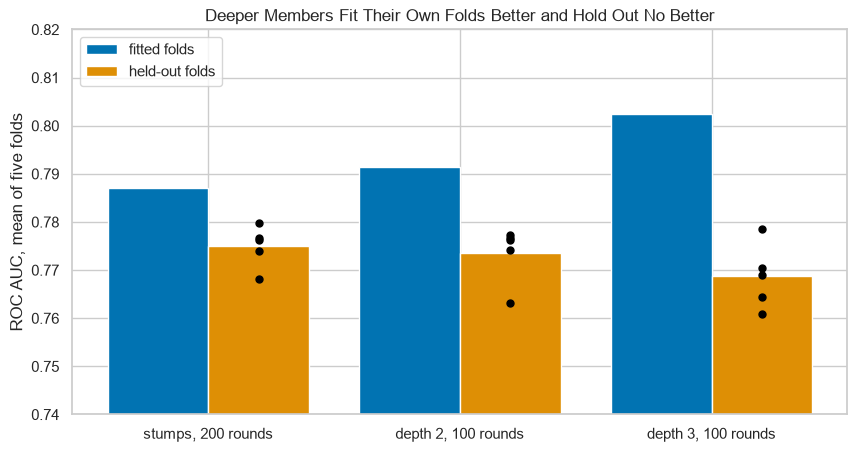

In [37]:
# fitted against held-out ROC AUC by member depth, each held-out fold as a dot
x = np.arange(3)
plt.bar(x - 0.2, depth_scores["fitted"], width=0.4, label="fitted folds")
plt.bar(x + 0.2, depth_scores["held out"], width=0.4, label="held-out folds")
for i, depth in enumerate(depth_scores.index):
    plt.scatter([i + 0.2] * 5, depth_scores.loc[depth, "folds"], color="black", s=25, zorder=3)
plt.xticks(x, ["stumps, 200 rounds", "depth 2, 100 rounds", "depth 3, 100 rounds"])
plt.ylim(0.74, 0.82)
plt.ylabel("ROC AUC, mean of five folds")
plt.title("Deeper Members Fit Their Own Folds Better and Hold Out No Better")
plt.legend(loc="upper left")
plt.show()

Fitted folds climb with depth, 0.7872 to 0.8024; held-out folds slip, 0.7749 to 0.7687.

The held-out folds of one depth spread about as wide as the gaps between depths.

**Stumps at rate 1.0 for 200 rounds stay the model: the folds chose it, never the validation rows.**

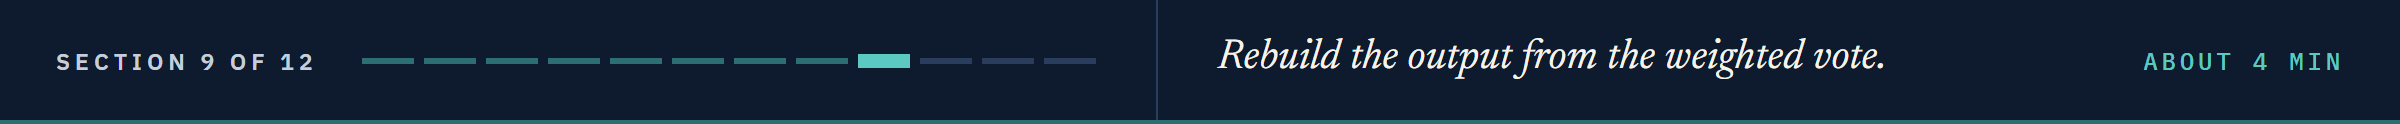

# A Weighted Vote, Not a Frequency

Each stump says yes (+1) or no (-1) about an account.
The **weighted vote** adds every stump's say times its weight and divides by the total weight, so it runs from -1, every stump saying no, to +1.

## The Vote by Hand

`says @ weights` multiplies each row of `says` by `weights` and adds along the row.
The members were fitted on arrays, so they take `X_valid.to_numpy()`, as in Day 2.

In [38]:
# each stump's say for each validation account, +1 for a flag and -1 for none
says = np.column_stack([2 * m.predict(X_valid.to_numpy()) - 1 for m in ada.estimators_])

# the weighted vote: says times weights, added, over the total weight
vote = says @ ada.estimator_weights_ / ada.estimator_weights_.sum()
print("Weighted vote: from", round(vote.min(), 4), "to", round(vote.max(), 4))

Weighted vote: from -0.4803 to 0.3243


In [39]:
# the library's two outputs against the vote
decision = ada.decision_function(X_valid)
score = ada.predict_proba(X_valid)[:, 1]
print("Largest gap, decision_function against twice the vote:", f"{np.abs(decision - 2 * vote).max():.1e}")
print("Largest gap, predict_proba against 1 / (1 + e^-decision):", f"{np.abs(score - 1 / (1 + np.exp(-decision))).max():.1e}")

Largest gap, decision_function against twice the vote: 8.9e-16
Largest gap, predict_proba against 1 / (1 + e^-decision): 1.1e-16


`decision_function` is twice the vote, and `predict_proba` is Course 4's Day 6 logistic curve of it.

The vote never leaves -1 to 1, so `predict_proba` never leaves 1 / (1 + e^2) to 1 / (1 + e^-2), about 0.12 to 0.88.

**Predict 5**

The validation default rate is 0.2212.

Q. What is the average of the model's `predict_proba` over the validation accounts? Write down a number.

## The Output Beside the Default Rate

In [40]:
# the output's average and range on the validation rows, and how many accounts reach 0.5
print("Default rate:", round(y_valid.mean(), 4), " Mean output:", round(score.mean(), 4))
print("Output from", round(score.min(), 4), "to", round(score.max(), 4), " At 0.5 or more:", (score >= 0.5).sum())
print("Median output, defaulted:", round(np.median(score[y_valid == 1]), 4), " paid:", round(np.median(score[y_valid == 0]), 4))

Default rate: 0.2212  Mean output: 0.4051
Output from 0.2768 to 0.6567  At 0.5 or more: 641
Median output, defaulted: 0.4396  paid: 0.3825


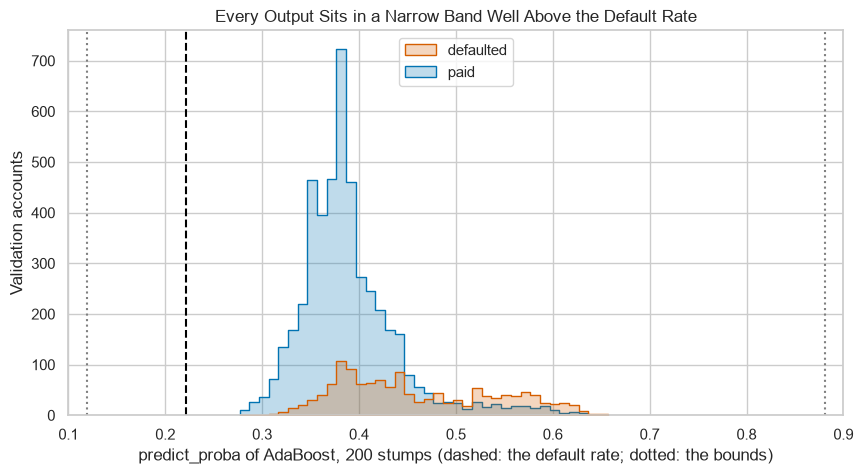

In [41]:
# the output by outcome, with the bounds and the default rate marked
sns.histplot(x=score, hue=y_valid.map({0: "paid", 1: "defaulted"}).to_numpy(), palette={"paid": "C0", "defaulted": "C3"},
             binwidth=0.01, element="step")
for bound in [1 / (1 + np.exp(2)), 1 / (1 + np.exp(-2))]:
    plt.axvline(bound, color="gray", linestyle=":")
plt.axvline(y_valid.mean(), color="black", linestyle="--")
plt.xlim(0.1, 0.9)
plt.xlabel("predict_proba of AdaBoost, 200 stumps (dashed: the default rate; dotted: the bounds)")
plt.ylabel("Validation accounts")
plt.title("Every Output Sits in a Narrow Band Well Above the Default Rate")
plt.show()

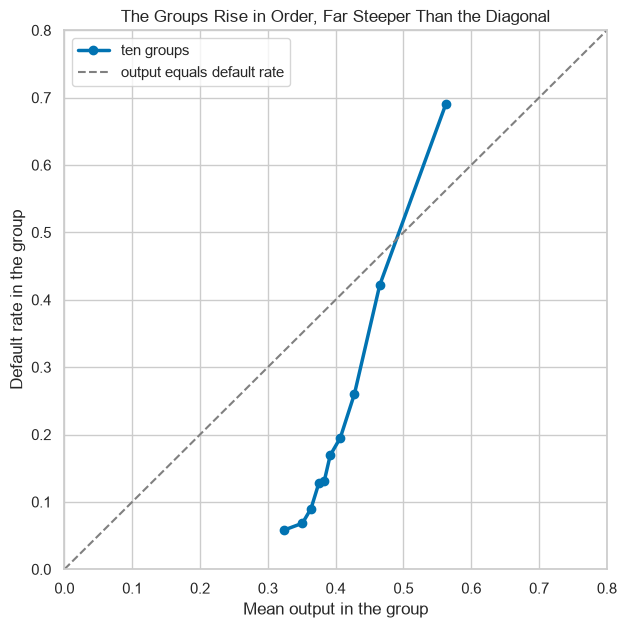

,0,1,2,3,4,5,6,7,8,9
mean output,0.3244,0.3510,0.3637,0.3754,0.3832,0.3920,0.4068,0.4278,0.4650,0.5623
default rate,0.0583,0.0683,0.0900,0.1283,0.1308,0.1692,0.1950,0.2604,0.4217,0.6900


In [42]:
# a reliability diagram: ten equal groups by output, each group's mean output against its default rate
tenth = pd.qcut(score, 10, labels=False)
reliability = pd.DataFrame({"mean output": score, "default rate": y_valid.to_numpy()}).groupby(tenth).mean()
plt.figure(figsize=(7, 7))
plt.plot(reliability["mean output"], reliability["default rate"], marker="o", linewidth=2.5, label="ten groups")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="output equals default rate")
plt.xlim(0, 0.8)
plt.ylim(0, 0.8)
plt.xlabel("Mean output in the group")
plt.ylabel("Default rate in the group")
plt.title("The Groups Rise in Order, Far Steeper Than the Diagonal")
plt.legend(loc="upper left")
plt.show()
reliability.T

The mean output is 0.4051 against a default rate of 0.2212, and 641 accounts reach 0.5.

The groups' mean outputs span 0.32 to 0.56 while their default rates span 0.06 to 0.69: the order is right, the level is not.

**The vote ranks accounts; its level is not a share of defaults, so we call it the model's score. Day 10 sets thresholds from out-of-fold scores, and Day 13 turns a score into a probability.**

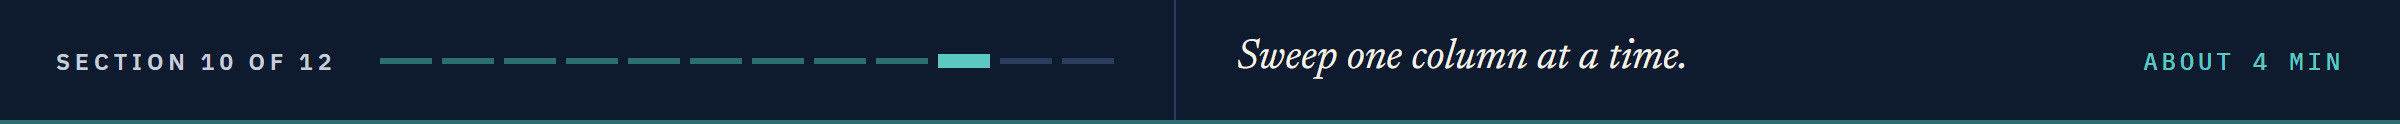

# What the Stumps Add Up To

A sum of stumps is an **additive model**: every stump reads one column, so the fit adds one column's steps to another's.
Each column's steps, added up, are its **shape function**.

## One Column at a Time

In [43]:
# rows that start from one account's values, with one column swept across its range: the model's output for each
# (method="lower" keeps every quantile a value the column really holds)
def sweep(column, start):
    values = np.unique(np.quantile(X_train[column], np.linspace(0, 1, 201), method="lower"))
    grid = pd.DataFrame([start] * len(values))
    grid[column] = values
    return values, ada.decision_function(grid)

In [44]:
# PAY_0 swept from the training medians, and from the first training account's values
values, from_medians = sweep("PAY_0", X_train.median())
values, from_account = sweep("PAY_0", X_train.iloc[0])
difference = from_account - from_medians
print("Spread of the difference between the two curves:", f"{difference.max() - difference.min():.1e}")
pd.Series(from_medians, index=values).round(3)

Spread of the difference between the two curves: 7.9e-16


-2   -0.4380
-1   -0.4380
 0   -0.4790
 1   -0.3530
 2    0.0830
 3    0.0830
 8   -0.0500
dtype: float64

The two curves differ by a constant: moving the other 18 columns shifts the curve, never its shape.

`PAY_0` moves the output from -0.479 at status 0 to 0.083 at status 2.

In [45]:
# how far each column's staircase moves the output, swept from the training medians, largest first
moves = {}
for column in FEATURES:
    values, decision_sweep = sweep(column, X_train.median())
    moves[column] = decision_sweep.max() - decision_sweep.min()
pd.Series(moves).sort_values(ascending=False).round(3)

PAY_0       0.5620
LIMIT_BAL   0.1830
PAY_AMT1    0.1810
PAY_3       0.1600
PAY_AMT2    0.1540
PAY_AMT3    0.1230
BILL_AMT1   0.1130
PAY_6       0.1040
PAY_4       0.0930
BILL_AMT2   0.0810
PAY_AMT5    0.0720
PAY_2       0.0720
PAY_5       0.0620
BILL_AMT6   0.0580
PAY_AMT4    0.0560
BILL_AMT3   0.0540
PAY_AMT6    0.0540
BILL_AMT5   0.0500
BILL_AMT4   0.0380
dtype: float64

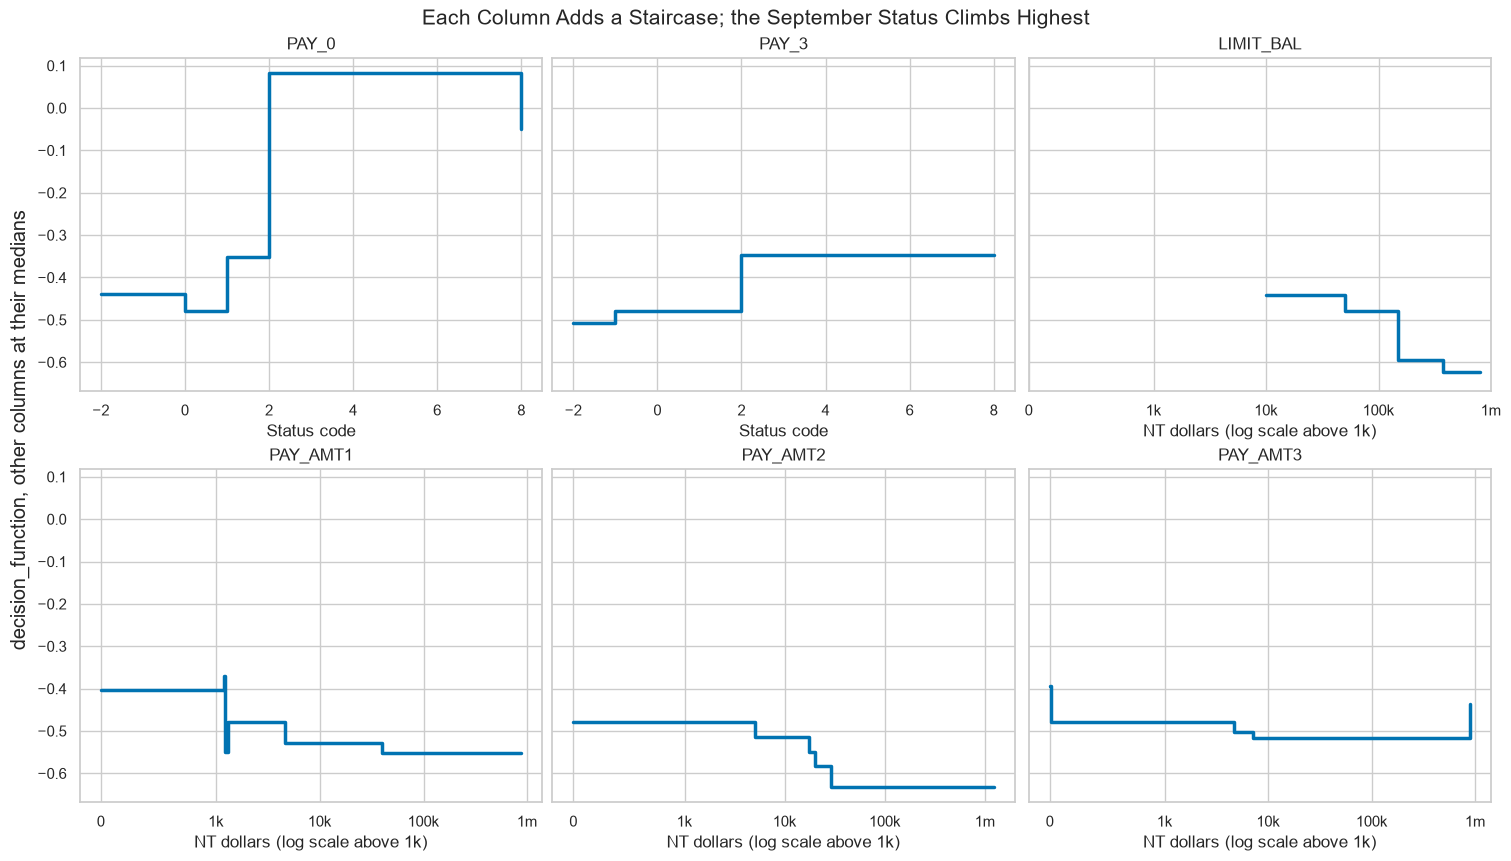

In [46]:
# the six tallest shape functions on one y scale; layout="constrained" keeps the panels' labels apart
# the money columns on a symlog axis, linear up to linthresh (1,000 NT dollars) and logarithmic above it
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharey=True, layout="constrained")
for ax, column in zip(axes.flat, ["PAY_0", "PAY_3", "LIMIT_BAL", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3"]):
    values, decision_sweep = sweep(column, X_train.median())
    ax.step(values, decision_sweep, where="post", linewidth=2.5)
    ax.set_title(column)
    if column in ["PAY_0", "PAY_3"]:
        ax.set_xlabel("Status code")
    else:
        ax.set_xscale("symlog", linthresh=1000)
        ax.set_xticks([0, 1e3, 1e4, 1e5, 1e6], ["0", "1k", "10k", "100k", "1m"])
        ax.set_xlabel("NT dollars (log scale above 1k)")
fig.supylabel("decision_function, other columns at their medians")
fig.suptitle("Each Column Adds a Staircase; the September Status Climbs Highest", fontsize=15)
plt.show()

`PAY_0` moves the output by 0.562, three times any other column.

The credit limit and the payments mostly step down as they rise.

Each staircase is association in this file, never a driver.

## Three Accounts' Votes

A **vote ledger** splits one account's vote by column: each stump's say times its weight, over the total, added by the column it asks.

In [47]:
# the lowest, a middle and the highest scored validation accounts, and the share of the vote each column gives them
picks = [score.argmin(), np.argsort(score)[len(score) // 2], score.argmax()]
outcome_name = {0: "paid", 1: "defaulted"}
names = [f"score {score[i]:.4f}, {outcome_name[y_valid.iloc[i]]}, PAY_0 {X_valid['PAY_0'].iloc[i]}" for i in picks]
ledger = pd.DataFrame((says[picks] * ada.estimator_weights_ / ada.estimator_weights_.sum()).T, index=asked.to_numpy(), columns=names)

# one row per stump, labelled by its column; groupby(level=0) adds the rows that share a label
ledger = ledger.groupby(level=0).sum()
ledger.loc[["PAY_0", "LIMIT_BAL", "PAY_AMT1"]].round(3)

,"score 0.2768, paid, PAY_0 0","score 0.3866, defaulted, PAY_0 0","score 0.6567, defaulted, PAY_0 3"
PAY_0,-0.1520,-0.1520,0.1290
LIMIT_BAL,-0.0460,-0.0320,0.0460
PAY_AMT1,-0.0450,0.0290,0.0290


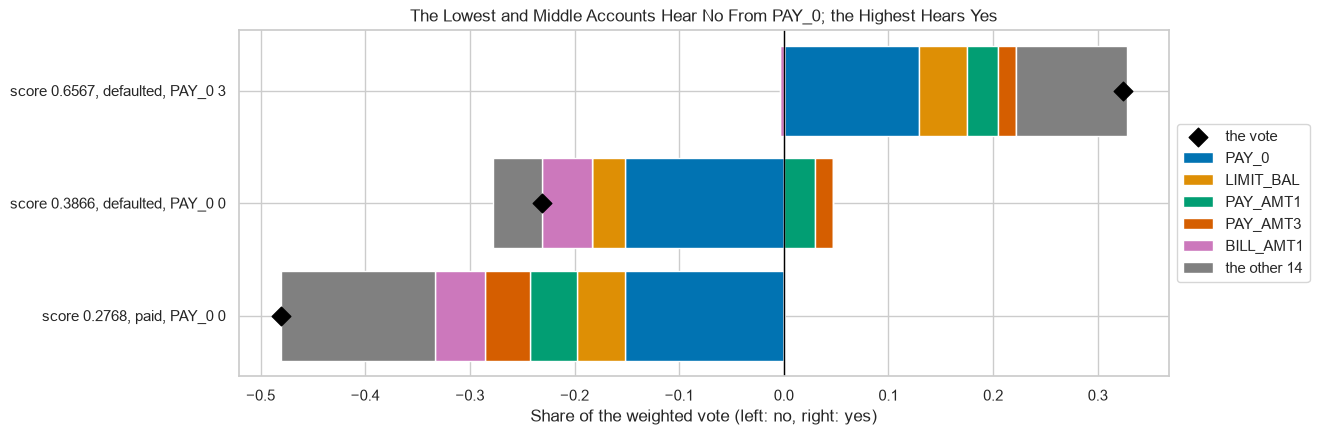

In [48]:
# a diverging stacked bar per account: the columns that push the vote up to the right, down to the left
main = ["PAY_0", "LIMIT_BAL", "PAY_AMT1", "PAY_AMT3", "BILL_AMT1"]
parts = pd.concat([ledger.loc[main], ledger.drop(index=main).sum().to_frame("the other 14").T])
yes, no = parts.clip(lower=0), parts.clip(upper=0)
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, column in enumerate(parts.index):
    colour = f"C{i}" if i < 5 else "gray"
    ax.barh(range(3), yes.loc[column], left=(yes.cumsum() - yes).loc[column], color=colour, label=column)
    ax.barh(range(3), no.loc[column], left=(no.cumsum() - no).loc[column], color=colour)
ax.scatter(parts.sum(), range(3), marker="D", s=90, color="black", zorder=3, label="the vote")
ax.axvline(0, color="black", linewidth=1)
ax.set(yticks=range(3), yticklabels=parts.columns, xlabel="Share of the weighted vote (left: no, right: yes)")
ax.set_title("The Lowest and Middle Accounts Hear No From PAY_0; the Highest Hears Yes")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

`PAY_0` gives -0.152 to the lowest and the middle account and +0.129 to the highest.

The middle account defaulted at status 0, yet its vote lands below zero, like every account scored below it.

**Two hundred stumps are nineteen staircases added up, and the September status is the tallest.**

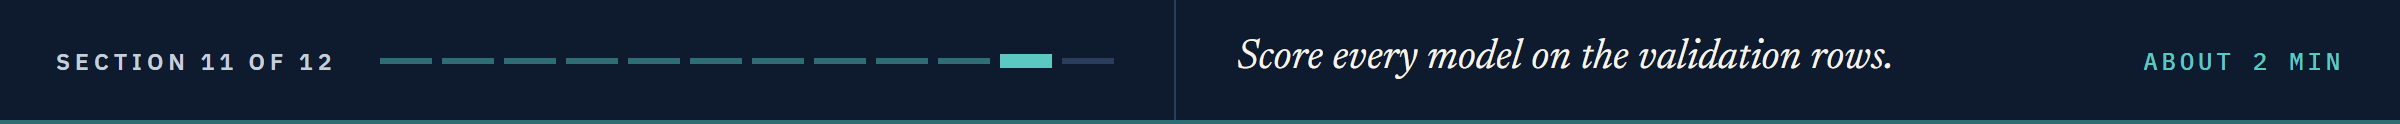

# Model Performance Comparison

## Validation Rows, Every Model

In [49]:
# Course 4's logistic regression and pruned tree, and Day 3's default and chosen forests
logistic = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
pruned = DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(X_train, y_train)
chosen_forest = RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, random_state=SEED,
                                       n_jobs=1).fit(X_train, y_train)

In [50]:
# every model on the validation rows, with its training ROC AUC and validation average precision beside it
models = {"Logistic regression": logistic, "Pruned tree": pruned, "Default forest": forest, "Chosen forest": chosen_forest,
          "One stump": stump, "AdaBoost, 50 stumps": ada50, "AdaBoost, 200 stumps": ada}
comparison = pd.concat([model_performance_classification(m, X_valid, y_valid) for m in models.values()])
comparison.index = list(models)
comparison["Training ROC AUC"] = [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in models.values()]
comparison["Average precision"] = [average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in models.values()]
comparison = comparison.sort_values("ROC AUC")
comparison

,ROC AUC,Accuracy,Recall,Precision,F1,Training ROC AUC,Average precision
One stump,0.6361,0.8160,0.3135,0.6831,0.4298,0.6459,0.3660
Logistic regression,0.7190,0.8123,0.2442,0.7248,0.3653,0.7296,0.4946
Default forest,0.7604,0.8150,0.3745,0.6396,0.4724,0.9996,0.5149
Pruned tree,0.7627,0.7683,0.5840,0.4805,0.5272,0.7691,0.4954
"AdaBoost, 50 stumps",0.7672,0.8168,0.3195,0.6839,0.4355,0.7760,0.5223
"AdaBoost, 200 stumps",0.7708,0.8177,0.3293,0.6817,0.4441,0.7867,0.5321
Chosen forest,0.7844,0.8192,0.3459,0.6790,0.4583,0.8204,0.5562


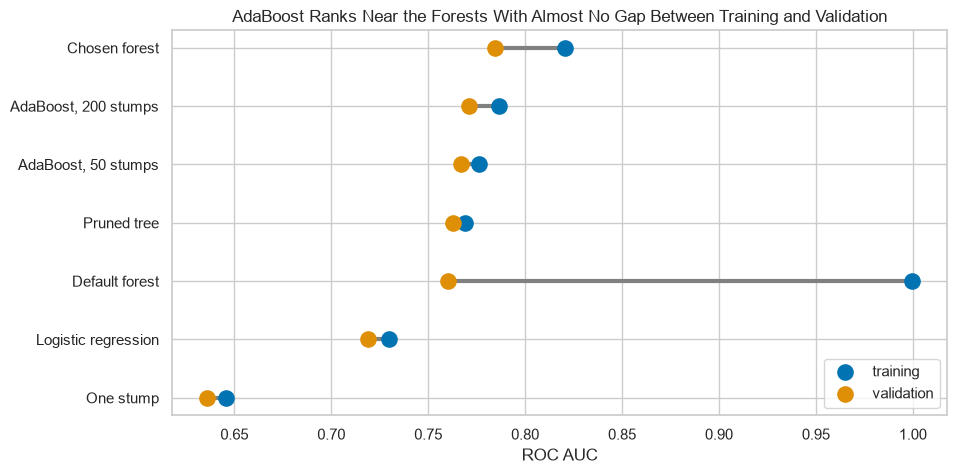

In [51]:
# a dumbbell per model: training against validation ROC AUC
fig, ax = plt.subplots(figsize=(10, 5))
ax.hlines(comparison.index, comparison["ROC AUC"], comparison["Training ROC AUC"], color="gray", linewidth=3)
ax.scatter(comparison["Training ROC AUC"], comparison.index, s=120, label="training", zorder=3)
ax.scatter(comparison["ROC AUC"], comparison.index, s=120, label="validation", zorder=3)
ax.set_xlabel("ROC AUC")
ax.set_title("AdaBoost Ranks Near the Forests With Almost No Gap Between Training and Validation")
ax.legend(loc="lower right")
plt.show()

AdaBoost with 200 stumps, 0.7708, passes Course 4's logistic regression and pruned tree and Day 3's default forest; Day 3's chosen forest still leads at 0.7844.

The default forest scores 0.9996 on its own rows; AdaBoost's training score sits under two hundredths above its validation score.

**The smallest trees, in sequence, rank about as well as week 1's forests with almost no gap. Day 7 replaces reweighting with fitting what is left.**

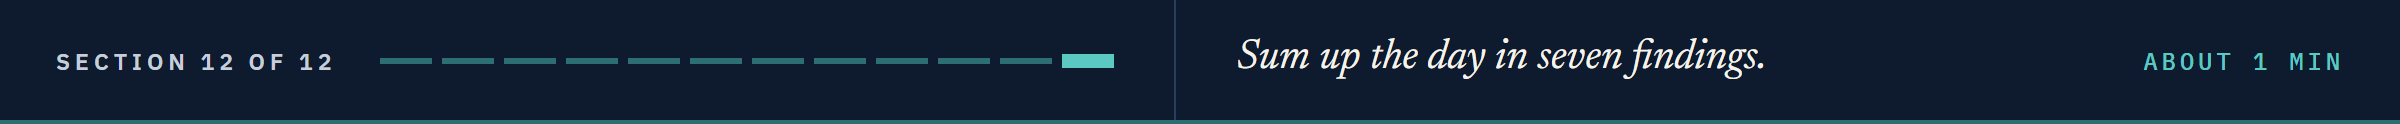

# Insights and Conclusion

One stump scores 0.6361 on validation rows, 50 stumps 0.7672, 200 stumps 0.7708.

A round is a weighted error, a stump's weight and a reweighting, matched to the library's digits.

At learning rate 1.0, every reweighting leaves the rows just missed with half the weight.

The weight piles onto defaulted accounts whose September status was not late.

The learning rate and the rounds trade; deeper members only fit their own folds better here.

The output is a bounded vote that ranks: the model's score, not a share of defaults.

The model is a sum of one-column staircases and leans on `PAY_0` most.

> STORY: Yoav Freund and Robert Schapire published AdaBoost as "A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting" in the Journal of Computer and System Sciences, volume 55, issue 1, pages 119 to 139, in August 1997. Source: https://api.crossref.org/works/10.1006/jcss.1997.1504

**Day 7 boosts by fitting each tree to what the trees before it still miss.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit `AdaBoostClassifier`, read its settings with `.get_params()`, and score it on training and validation rows.
* Run one round of AdaBoost by hand: weighted error, the stump's weight, the new row weights.
* Follow where the row weights go and which column each round asks.
* Read the rounds, the learning rate and the member's depth from folds inside the training rows.
* Rebuild the model's output from its weighted vote, and take the model apart one column at a time.

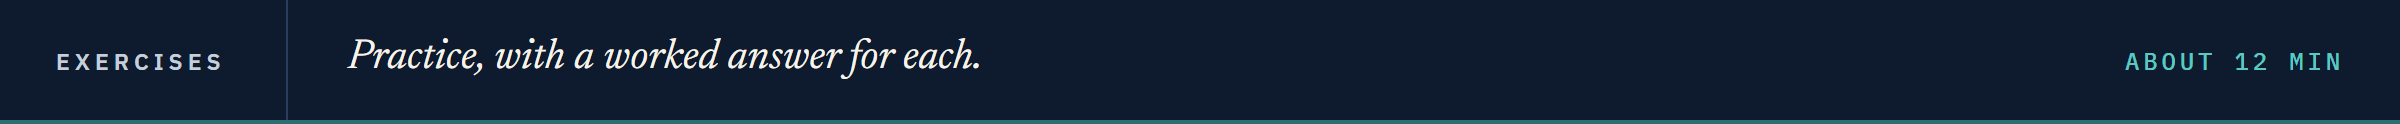

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [52]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Depth-2 Members on the Validation Rows**

Q. Fit `boosted(depth=2, rounds=100)` on the training rows and store its validation ROC AUC in `ex1_auc`.

In [53]:
# your code here
ex1_auc = ...

In [54]:
check("Exercise 1 depth-2 members", ex1_auc, 0.7739717864865601)

Exercise 1 depth-2 members: not attempted yet


### Exercise 2

**Enough Rounds**

Q. Using `curves`, find the first round at which the rate-1.0 curve comes within 0.001 of its highest value, and store it in `ex2_round`.

In [55]:
# your code here
ex2_round = ...

In [56]:
check("Exercise 2 the first round within 0.001", ex2_round, 150)

Exercise 2 the first round within 0.001: not attempted yet


### Exercise 3

**A Function for the Weighted Error**

Q. Write `weighted_error(weights, missed)` that returns the share of the weight on the missed rows, and store `weighted_error(history[0], missed)` in `ex3_error`.

In [57]:
# your code here
ex3_error = ...

In [58]:
check("Exercise 3 round one's weighted error", ex3_error, 0.17905555555555558)

Exercise 3 round one's weighted error: not attempted yet


### Exercise 4: AI check

**The Stump That Spoke Too Softly**

You asked an AI assistant for a function that turns a stump's weighted error into its weight in the vote.
This came back.
It runs, and it gives a positive weight.
Test it, then find the one bug.

In [59]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def stump_weight(error):
    # the stump's say in the vote, from its weighted error
    return np.log10((1 - error) / error)

ai_weight = stump_weight(ada.estimator_errors_[0])
print("Stump's weight:", round(ai_weight, 4))

Stump's weight: 0.6613


In [60]:
# the test: the first stump's weight must equal the library's
assert abs(ai_weight - ada.estimator_weights_[0]) < 1e-9, "not the library's weight for the first stump"

AssertionError: not the library's weight for the first stump

Q. Fix the function, and store `stump_weight(ada.estimator_errors_[0])` in `ex4_weight`.

In [61]:
# your code here
ex4_weight = ...

In [62]:
check("Exercise 4 the first stump's weight", ex4_weight, 1.522759315088196)

Exercise 4 the first stump's weight: not attempted yet


## Congratulations!

You took boosting apart round by round.
You ran a round by hand and matched scikit-learn's digits, then watched the weight gather on the accounts no early question could see.
You read the rounds, the learning rate and the depth from folds, rebuilt the output from a weighted vote, and saw that it ranks without being a share of defaults.
Two hundred one-question trees ranked about as well as week 1's forests.
In Day 7 each new tree fits what the trees before it still miss.

[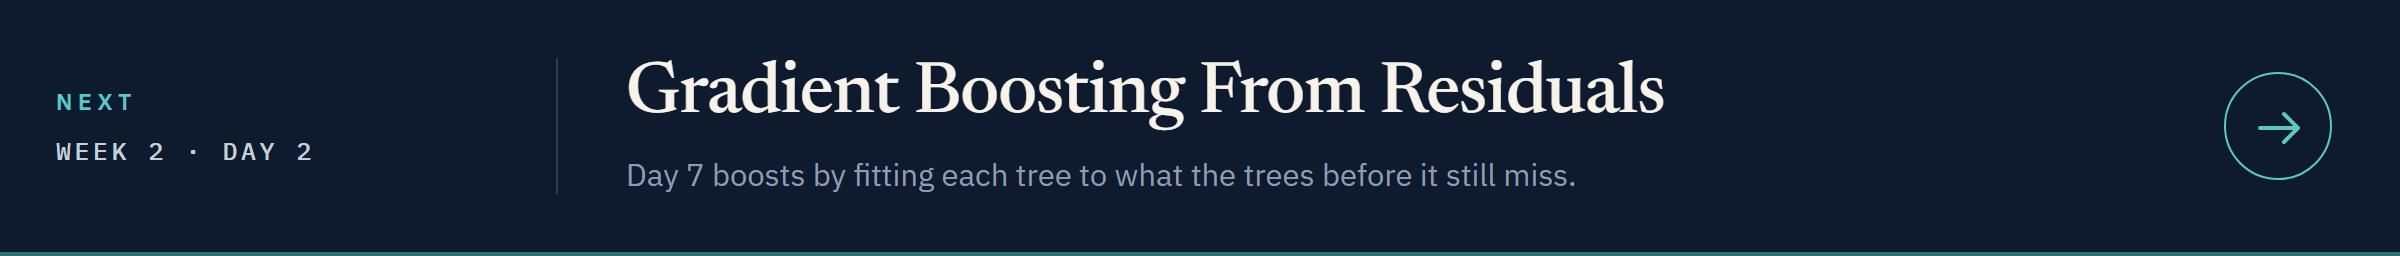](../day2/07_gradient_boosting_from_residuals.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day2/07_gradient_boosting_from_residuals.ipynb)